# Portfolio Project 1 — E-commerce Sales Analytics

## 1. Introduction

### Мета проекту
Цей проект присвячений аналізу продажів інтернет-магазину меблів (IKEA-подібний асортимент).
Мета — дослідити поведінку користувачів, динаміку продажів та ключові метрики бізнесу
за період з листопада 2020 по січень 2021 року.

### Завдання проекту
- Вивантажити та підготувати дані з Google BigQuery за допомогою SQL
- Провести розвідувальний аналіз даних (EDA)
- Дослідити географію продажів, поведінку користувачів та джерела трафіку
- Провести статистичний аналіз взаємозв'язків та відмінностей між групами
- Побудувати аналітичний дашборд у Tableau Public

### Джерело даних
Дані надані у вигляді реляційної бази даних Google BigQuery (датасет DA).
База містить інформацію про сесії користувачів, замовлення, товари,
зареєстровані акаунти та email-маркетинг.

### Структура ноутбука
| # | Розділ | Опис |
|---|--------|------|
| 2 | Environment Setup | Імпорти, підключення до БД, SQL запит |
| 3 | Data Overview | Загальний огляд датасету |
| 4 | Data Cleaning | Очищення та підготовка даних |
| 5 | EDA | Аналіз метрик: гео, товари, трафік, користувачі |
| 6 | Sales Dynamics | Динаміка продажів у часі |
| 7 | Pivot Tables | Зведені таблиці |
| 8 | Correlation Analysis | Статистичний аналіз взаємозв'язків |
| 9 | Statistical Tests | Тести на відмінності між групами |
| 10 | Conclusions | Висновки та інсайти |





##Дашборд: https://public.tableau.com/app/profile/taras.kubitskyi/viz/E-commerceSalesAnalyticsPortfolioProject/Overview

## 2. Environment Setup

In [240]:
# Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from google.cloud import bigquery

from google.colab import auth
auth.authenticate_user()

# Статистика
from scipy import stats
from itertools import combinations


### Підключення до BigQuery


In [241]:
# Підключення
project_id = 'project-sales-2026'
client = bigquery.Client(project='project-sales-2026')

### Query 1 — Traffic & Users (df_traffic)
Датафрейм містить усі сесії з інформацією про трафік, девайси та зареєстрованих користувачів.
Використовується для аналізу поведінки користувачів, географії трафіку та метрик акаунтів.

In [242]:
query_traffic = """
SELECT
    s.date AS order_date,
    s.ga_session_id,
    sp.continent,
    sp.country,
    sp.device,
    sp.browser,
    sp.mobile_model_name,
    sp.operating_system,
    sp.language,
    sp.medium AS traffic_medium,
    sp.name   AS traffic_source_name,
    sp.channel AS traffic_channel,
    ac.id AS registered_user_id,
    ac.is_verified AS is_email_confirmed,
    ac.is_unsubscribed
FROM `DA.session` s
LEFT JOIN `DA.session_params` sp  ON s.ga_session_id = sp.ga_session_id
LEFT JOIN `DA.account_session` acs ON s.ga_session_id = acs.ga_session_id
LEFT JOIN `DA.account` ac          ON acs.account_id  = ac.id
"""

df_traffic = client.query(query_traffic).to_dataframe()
print(f"df_traffic: {df_traffic.shape[0]:,} рядків × {df_traffic.shape[1]} колонок")

df_traffic: 349,545 рядків × 15 колонок


### Query 2 — Sales (df_sales)
Датафрейм містить усі замовлення з інформацією про товари, категорії та ціни.
Використовується для аналізу продажів, динаміки виручки та категорій товарів.

In [243]:
query_sales = """
SELECT
    o.ga_session_id,
    o.item_id,
    p.category AS product_category,
    p.name     AS product_name,
    p.price,
    p.short_description AS product_description,
    s.date AS order_date,
    sp.continent,
    sp.country,
    sp.device,
    sp.channel AS traffic_channel,
    CASE WHEN acs.account_id IS NOT NULL THEN TRUE ELSE FALSE END AS is_registered
FROM `DA.order` o
INNER JOIN `DA.product` p          ON o.item_id     = p.item_id
LEFT JOIN  `DA.session` s          ON o.ga_session_id = s.ga_session_id
LEFT JOIN  `DA.session_params` sp  ON o.ga_session_id = sp.ga_session_id
LEFT JOIN  `DA.account_session` acs ON o.ga_session_id = acs.ga_session_id
"""

df_sales = client.query(query_sales).to_dataframe()
print(f"df_sales: {df_sales.shape[0]:,} рядків × {df_sales.shape[1]} колонок")

df_sales: 33,538 рядків × 12 колонок


In [244]:
print("=== df_traffic ===")
print(df_traffic.head(3))
print("\n=== df_sales ===")
print(df_sales.head(3))

=== df_traffic ===
   order_date  ga_session_id continent        country   device browser  \
0  2020-11-01     5521858682  Americas  United States  desktop  Chrome   
1  2020-11-01     1819600414  Americas  United States   mobile  Safari   
2  2020-11-01      505070303  Americas  United States   mobile  Chrome   

  mobile_model_name operating_system language  traffic_medium  \
0            Safari        Macintosh    en-us  (data deleted)   
1            iPhone              iOS    en-us  (data deleted)   
2           <Other>          Android    en-us  (data deleted)   

  traffic_source_name traffic_channel  registered_user_id  is_email_confirmed  \
0      (data deleted)       Undefined                <NA>                <NA>   
1      (data deleted)       Undefined                <NA>                <NA>   
2      (data deleted)       Undefined                <NA>                <NA>   

   is_unsubscribed  
0             <NA>  
1             <NA>  
2             <NA>  

=== df_sales 

In [245]:
print(f"df_traffic: {df_traffic.shape}")
print(f"df_sales: {df_sales.shape}")

df_traffic: (349545, 15)
df_sales: (33538, 12)


## 3. Data Overview

In [246]:
# Загальна інформація
print(f"Розмір датасету: {df_traffic.shape[0]:,} рядків × {df_traffic.shape[1]} колонок")
print(f"Період даних: {df_traffic['order_date'].min()} → {df_traffic['order_date'].max()}")
print(f"Унікальних сесій: {df_traffic['ga_session_id'].nunique():,}")
print(f"Унікальних замовлень: {df_sales['product_name'].notna().sum():,}")
print(f"Зареєстрованих користувачів: {df_traffic['registered_user_id'].notna().sum():,}")

Розмір датасету: 349,545 рядків × 15 колонок
Період даних: 2020-11-01 → 2021-01-31
Унікальних сесій: 349,545
Унікальних замовлень: 33,538
Зареєстрованих користувачів: 27,945


In [247]:
# Типи колонок
df_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   order_date           349545 non-null  dbdate
 1   ga_session_id        349545 non-null  Int64 
 2   continent            349545 non-null  object
 3   country              349545 non-null  object
 4   device               349545 non-null  object
 5   browser              349545 non-null  object
 6   mobile_model_name    349545 non-null  object
 7   operating_system     349545 non-null  object
 8   language             235279 non-null  object
 9   traffic_medium       349545 non-null  object
 10  traffic_source_name  349545 non-null  object
 11  traffic_channel      349545 non-null  object
 12  registered_user_id   27945 non-null   Int64 
 13  is_email_confirmed   27945 non-null   Int64 
 14  is_unsubscribed      27945 non-null   Int64 
dtypes: Int64(4), dbdate(1), object(10)

In [248]:
df_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33538 entries, 0 to 33537
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ga_session_id        33538 non-null  Int64  
 1   item_id              33538 non-null  Int64  
 2   product_category     33538 non-null  object 
 3   product_name         33538 non-null  object 
 4   price                33538 non-null  float64
 5   product_description  33538 non-null  object 
 6   order_date           33538 non-null  dbdate 
 7   continent            33538 non-null  object 
 8   country              33538 non-null  object 
 9   device               33538 non-null  object 
 10  traffic_channel      33538 non-null  object 
 11  is_registered        33538 non-null  boolean
dtypes: Int64(2), boolean(1), dbdate(1), float64(1), object(7)
memory usage: 2.9+ MB


In [249]:
# Статистика числових колонок
print("=== df_traffic ===")
df_traffic[['is_email_confirmed', 'is_unsubscribed']].describe().round(2)

=== df_traffic ===


,is_email_confirmed,is_unsubscribed
count,27945.0,27945.0
mean,0.72,0.17
std,0.45,0.38
min,0.0,0.0
25%,0.0,0.0
50%,1.0,0.0
75%,1.0,0.0
max,1.0,1.0


In [250]:
print("df_sales")
df_sales[['price']].describe().round(2)

df_sales


,price
count,33538.0
mean,953.3
std,1317.0
min,3.0
25%,170.0
50%,445.0
75%,1195.0
max,9585.0


In [251]:
# Пропущені значення
print(" DF_traffic — пропущені значення (%) ")
missing_traffic = (df_traffic.isna().mean() * 100).round(2).sort_values(ascending=False)
print(missing_traffic[missing_traffic > 0])

print("\n DF_sales — пропущені значення (%) ")
missing_sales = (df_sales.isna().mean() * 100).round(2).sort_values(ascending=False)
print(missing_sales[missing_sales > 0])

 DF_traffic — пропущені значення (%) 
registered_user_id    92.01
is_unsubscribed       92.01
is_email_confirmed    92.01
language              32.69
dtype: float64

 DF_sales — пропущені значення (%) 
Series([], dtype: float64)


**Коментар до пропущених значень:**

df_traffic:
- `registered_user_id / is_email_confirmed / is_unsubscribed` — 92% пропусків.
  Норма: більшість відвідувачів не реєструються на сайті.
- `language` — 33% пропусків. Браузер не завжди передає мову.

df_sales:
- Пропущених значень немає (0%).
  INNER JOIN з таблицею order гарантує що в датасеті
  тільки повні записи про реальні замовлення.

In [252]:
# Унікальні значення категоріальних колонок
def show_categorical(df, name):
    print(f"{'='*100}")
    print(f"  {name}")
    print(f"{'='*100}")
    categorical_cols = df.select_dtypes(include=['object']).columns

    for col in categorical_cols:
        n_unique = df[col].nunique()
        vals = df[col].unique()
        print(f"--- {col} ({n_unique} унікальних) ---")
        if n_unique < 30:
            print(vals)
        else:
            print(f"Перші 10 значень: {vals[:10]}")
        print()

show_categorical(df_traffic, 'df_traffic')
show_categorical(df_sales, 'df_sales')

  df_traffic
--- continent (6 унікальних) ---
['Americas' 'Asia' 'Europe' 'Africa' 'Oceania' '(not set)']

--- country (108 унікальних) ---
Перші 10 значень: ['United States' 'India' 'United Kingdom' 'France' 'Peru' 'Finland'
 'Canada' 'Vietnam' 'Taiwan' 'Netherlands']

--- device (3 унікальних) ---
['desktop' 'mobile' 'tablet']

--- browser (6 унікальних) ---
['Chrome' 'Safari' 'Firefox' '<Other>' 'Edge' 'Android Webview']

--- mobile_model_name (10 унікальних) ---
['Safari' 'iPhone' '<Other>' 'Chrome' 'ChromeBook' 'iPad' 'Firefox' 'Edge'
 'Pixel 3' 'Pixel 4 XL']

--- operating_system (6 унікальних) ---
['Macintosh' 'iOS' 'Android' 'Web' 'Windows' '<Other>']

--- language (9 унікальних) ---
['en-us' 'en-ca' None 'en-gb' 'en' 'fr' 'es-es' 'de' 'zh' 'ko']

--- traffic_medium (6 унікальних) ---
['(data deleted)' '(none)' '<Other>' 'cpc' 'organic' 'referral']

--- traffic_source_name (5 унікальних) ---
['(data deleted)' '<Other>' '(direct)' '(organic)' '(referral)']

--- traffic_channel (

### Підсумок огляду датасету

#### df_traffic — сесії та користувачі

| Характеристика | Значення |
|----------------|----------|
| Кількість рядків | 349,545 |
| Кількість колонок | 15 |
| Числові колонки (2) | `ga_session_id`, `registered_user_id` |
| Категоріальні колонки (10) | `continent`, `country`, `device`, `browser`, `mobile_model_name`, `operating_system`, `language`, `traffic_medium`, `traffic_source_name`, `traffic_channel` |
| Булеві колонки (2) | `is_email_confirmed`, `is_unsubscribed` |
| Datetime колонки (1) | `order_date` |
| Період | 2020-11-01 → 2021-01-31 |
| Унікальних сесій | 349,545 |
| Зареєстрованих користувачів | 27,945 (~8%) |
| Унікальних країн | 108 |
| Унікальних континентів | 6 |

#### df_sales — замовлення та товари

| Характеристика | Значення |
|----------------|----------|
| Кількість рядків | 33,538 |
| Кількість колонок | 12 |
| Числові колонки (2) | `ga_session_id`, `price` |
| Категоріальні колонки (7) | `product_category`, `product_name`, `product_description`, `continent`, `country`, `device`, `traffic_channel` |
| Булеві колонки (1) | `is_registered` |
| Datetime колонки (1) | `order_date` |
| Конверсія сесій у покупку | ~9.6% |
| Унікальних категорій товарів | 14 |
| Унікальних товарів | 550 |
| Пропущених значень | 0% |

## 4. Data Cleaning

In [253]:
# Дублікати
print(f"Кількість дублікатів df_traffic: {df_traffic.duplicated().sum()}")
print(f"Кількість дублікатів df_sales: {df_sales.duplicated().sum()}")

Кількість дублікатів df_traffic: 0
Кількість дублікатів df_sales: 0


In [254]:
# Стандартизація назв колонок
def clean_columns(df):
    df = df.copy()
    df.columns = (
        df.columns
        .str.lower()
        .str.strip()
        .str.replace(r"[^\w]+", "_", regex=True)
    )
    return df

df_traffic = clean_columns(df_traffic)
df_sales = clean_columns(df_sales)

print("df_traffic колонки:", df_traffic.columns.tolist())
print("df_sales колонки:", df_sales.columns.tolist())

df_traffic колонки: ['order_date', 'ga_session_id', 'continent', 'country', 'device', 'browser', 'mobile_model_name', 'operating_system', 'language', 'traffic_medium', 'traffic_source_name', 'traffic_channel', 'registered_user_id', 'is_email_confirmed', 'is_unsubscribed']
df_sales колонки: ['ga_session_id', 'item_id', 'product_category', 'product_name', 'price', 'product_description', 'order_date', 'continent', 'country', 'device', 'traffic_channel', 'is_registered']


In [255]:
# Колонка language
# Крок 1 — заповнюємо пропуски
df_traffic['language'] = df_traffic['language'].fillna('unknown')

# Крок 2 — обрізаємо до 2 літер (en-us → en), unknown не чіпаємо
df_traffic['language'] = df_traffic['language'].apply(lambda x: x[:2] if x != 'unknown' else x)

# Крок 3 — нижній регістр
df_traffic['language'] = df_traffic['language'].str.lower()

print("Унікальні значення language після очищення:")
print(df_traffic['language'].value_counts().head(10))

Унікальні значення language після очищення:
language
en         205517
unknown    114266
zh          12222
es           5760
fr           5652
de           3387
ko           2741
Name: count, dtype: int64


**Коментар:**
Мова браузера відсутня у ~ 33% сесій. Аналіз показав, що пропуски
рівномірно розподілені між країнами (~32% у кожній), тобто це
системна особливість збору даних, а не аномалія конкретного регіону.
Пропуски заповнені значенням `unknown` для коректної роботи з групуванням.

In [256]:
# Колонка order_date — конвертуємо в datetime
df_traffic['order_date'] = pd.to_datetime(df_traffic['order_date'])
df_sales['order_date'] = pd.to_datetime(df_sales['order_date'])

print(f"df_traffic order_date: {df_traffic['order_date'].dtype}")
print(f"df_sales order_date: {df_sales['order_date'].dtype}")

df_traffic order_date: datetime64[ns]
df_sales order_date: datetime64[ns]


In [257]:
last_order_date = df_sales['order_date'].max()
print(f"Остання дата замовлень: {last_order_date.date()}")

df_traffic = df_traffic[df_traffic['order_date'] <= last_order_date]
print(f"Сесій після обрізки: {len(df_traffic):,}")

Остання дата замовлень: 2021-01-27
Сесій після обрізки: 336,076


In [258]:
# Фінальна перевірка після очищення
print(f"Розмір датасету df_traffic: {df_traffic.shape}")
print(f"Розмір датасету df_sales: {df_sales.shape}")
print(f"Пропуски після очищення:")
print((df_traffic.isna().mean() * 100).round(2).sort_values(ascending=False)[lambda x: x > 0])
print((df_sales.isna().mean() * 100).round(2).sort_values(ascending=False)[lambda x: x > 0])

Розмір датасету df_traffic: (336076, 15)
Розмір датасету df_sales: (33538, 12)
Пропуски після очищення:
registered_user_id    91.68
is_unsubscribed       91.68
is_email_confirmed    91.68
dtype: float64
Series([], dtype: float64)


### Підсумок Data Cleaning

| Дія | Результат |
|-----|-----------|
| Перевірка дублікатів | 0 дублікатів |
| Стандартизація колонок | назви приведені до `snake_case` |
| Обробка `language` | пропуски → `unknown`, обрізка до 2 літер |
| Конвертація `order_date` | `dbdate` → `datetime64` |

In [259]:
sessions_with_orders = df_sales['ga_session_id'].nunique()
total_sessions = len(df_traffic)

conversion_rate = sessions_with_orders / total_sessions * 100
print(f"Конверсія сесій у замовлення: {conversion_rate:.1f}%")
print(f"Сесій без замовлення: {total_sessions - sessions_with_orders:,} ({100-conversion_rate:.1f}%)")

Конверсія сесій у замовлення: 10.0%
Сесій без замовлення: 302,538 (90.0%)


**Коментар до конверсії сесій у замовлення:**
- Конверсія сесій у замовлення становить 10,0% (після узгодження періоду сесій з таблицею замовлень). Це вище за типові для e-commerce 2–5%, але датасет навчальний, тож порівняння з ринковим бенчмарком орієнтовне.
- Сесій без замовлення — 302 538 (90,0%). У df_sales це не проявляється як пропуски, оскільки датасет побудований через INNER JOIN з таблицею order, а там за визначенням не може бути рядка без замовлення.
- Гіпотетичний сценарій: якби при з'єднанні двох датасетів (df_traffic + df_sales) використати LEFT JOIN (від сесій), то товарні поля (product_category, price тощо) мали б ~90% пропусків, саме через ці 302 538 сесій без замовлення.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Географія продажів

In [260]:
# Топ-5 континенти за продажами та кількістю замовлень
continent_sales = (df_sales.groupby('continent')
                   .agg(total_sales=('price', 'sum'),
                        total_orders=('price', 'count'))
                   .sort_values('total_sales', ascending=False)
                   .head(5))

continent_sales['total_sales'] = continent_sales['total_sales'].round(2)
print("Топ-5 континенти:")
print(continent_sales)

Топ-5 континенти:
           total_sales  total_orders
continent                           
Americas    17665280.0         18553
Asia         7601298.3          7950
Europe       5934624.2          6261
Oceania       365230.2           364
Africa        331231.0           339


In [261]:
# Топ-5 країн за продажами та кількістю замовлень
country_sales = (df_sales.groupby('country')
                 .agg(total_sales=('price', 'sum'),
                      total_orders=('price', 'count'))
                 .sort_values('total_sales', ascending=False)
                 .head(5))

country_sales['total_sales'] = country_sales['total_sales'].round(2)
print("Топ-5 країн:")
print(country_sales)

Топ-5 країн:
                total_sales  total_orders
country                                  
United States    13943553.9         14673
India             2809762.0          3029
Canada            2437921.0          2560
United Kingdom     938317.9          1029
France             710692.8           678


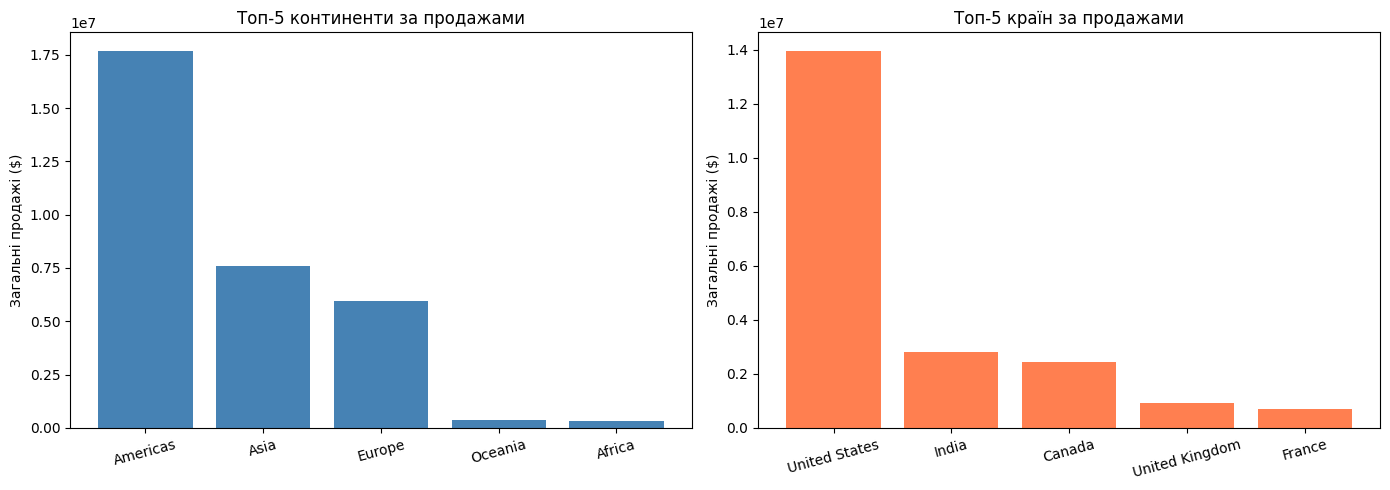

In [262]:
# Візуалізація
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Континенти
axes[0].bar(continent_sales.index, continent_sales['total_sales'], color='steelblue')
axes[0].set_title('Топ-5 континенти за продажами')
axes[0].set_ylabel('Загальні продажі ($)')
axes[0].tick_params(axis='x', rotation=15)

# Країни
axes[1].bar(country_sales.index, country_sales['total_sales'], color='coral')
axes[1].set_title('Топ-5 країн за продажами')
axes[1].set_ylabel('Загальні продажі ($)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

За обсягом продажів беззаперечним лідером є Америка - 17.7 млн дол. та 18 553 замовлення, що становить близько 55% від загального обсягу продажів компанії. Друге місце займає Азія 7.6 млн, третє - Європа 5.9 млн. Регіони Океанія та Африка демонструють найнижчі показники продажів.

На рівні окремих країн домінують США - 13.9 млн дол. продажів та 14 673 замовлення, що становить майже половину світового виторгу компанії. Зі значним відривом далі розташовуються Індія 2.8 мл, Канада 2.4 млн, Велика Британія 0.9 млн та Франція 0.7 млн.

Обсяг продажів у США перевищує сукупні продажі в Азії та Європі. Це свідчить про високу концентрацію доходів на одному ринку та значну залежність компанії від американського сегмента. Для зниження ризиків і забезпечення подальшого зростання доцільно розглянути посилення присутності на ринках Азії та Європи, де існує потенціал для масштабування продажів.


### 5.2 Категорії товарів

In [263]:
# Топ-10 категорій за загальними продажами
top_categories = (df_sales.groupby('product_category')['price']
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

print("Топ-10 категорій товарів:")
print(top_categories.round(2))

Топ-10 категорій товарів:
product_category
Sofas & armchairs                   8388254.5
Chairs                              6147748.8
Beds                                4919725.0
Bookcases & shelving units          3640818.1
Cabinets & cupboards                2336499.5
Outdoor furniture                   2142222.2
Tables & desks                      1790307.5
Chests of drawers & drawer units     906562.5
Bar furniture                        735503.0
Children's furniture                 467697.0
Name: price, dtype: float64


In [264]:
# Топ-10 категорій у країні з найбільшими продажами
top_country = country_sales.index[0]

top_cat_country = (df_sales[df_sales['country'] == top_country]
                   .groupby('product_category')['price']
                   .sum()
                   .sort_values(ascending=False)
                   .head(10))

print(f"Топ-10 категорій у {top_country}:")
print(top_cat_country.round(2))

Топ-10 категорій у United States:
product_category
Sofas & armchairs                   3707144.5
Chairs                              2619773.8
Beds                                2213058.0
Bookcases & shelving units          1567606.9
Cabinets & cupboards                 994545.5
Outdoor furniture                    929245.2
Tables & desks                       777865.0
Chests of drawers & drawer units     382388.0
Bar furniture                        330805.0
Children's furniture                 207575.0
Name: price, dtype: float64


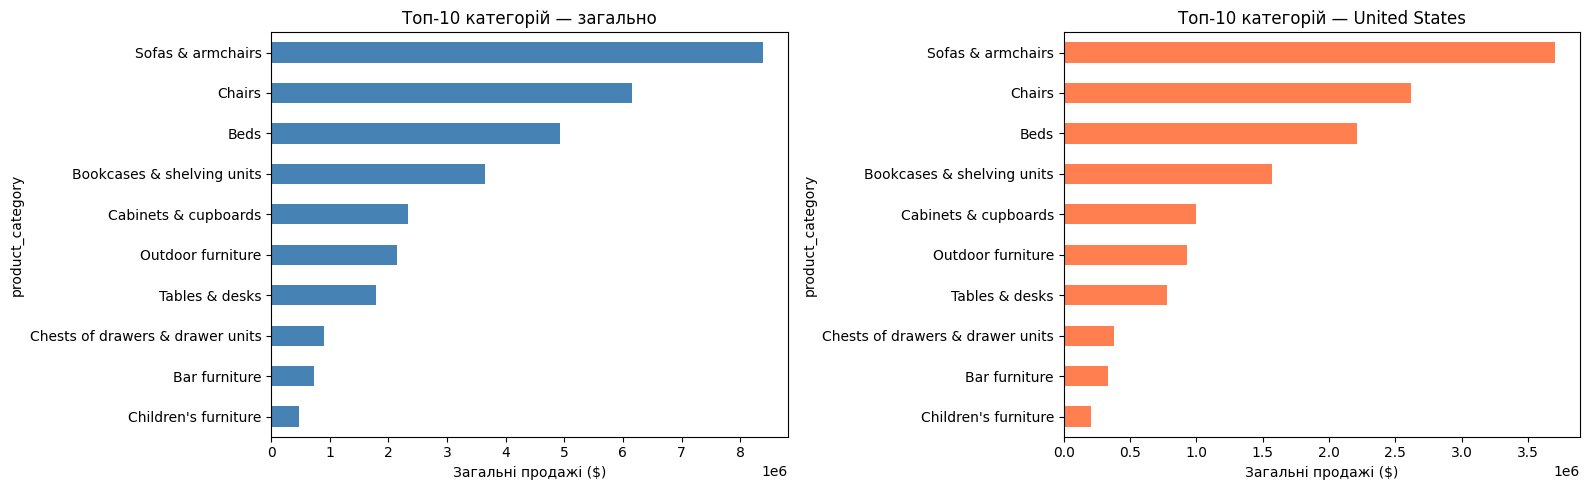

In [265]:
# Візуалізація — порівняння
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_categories.sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Топ-10 категорій — загально')
axes[0].set_xlabel('Загальні продажі ($)')

top_cat_country.sort_values().plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title(f'Топ-10 категорій — {top_country}')
axes[1].set_xlabel('Загальні продажі ($)')

plt.tight_layout()
plt.show()

**Висновок:**
- Лідер -  Sofas & armchairs 8.4 млн, далі Chairs 6.1 млн і Beds 4.9 млн
- У США структура ідентична - ті самі топ-3 категорії
- Топ-10 категорій загально і в США майже повністю збігаються

Меблі для сидіння та сну - основний драйвер продажів

### 5.3 Девайси та браузери

In [266]:
# Продажі за типами девайсів (%)
device_sales = (df_sales.groupby('device')['price']
                .sum()
                .sort_values(ascending=False))

device_pct = (device_sales / device_sales.sum() * 100).round(2)
print("Продажі за девайсами (%):")
print(device_pct)

Продажі за девайсами (%):
device
desktop    59.00
mobile     38.73
tablet      2.26
Name: price, dtype: float64


In [267]:
# Додаємо browser з df_traffic до df_sales
browser_col = df_traffic[['ga_session_id', 'browser']]
df_sales_browser = df_sales.merge(browser_col, on='ga_session_id', how='left')

# Продажі за браузерами
browser_sales = (df_sales_browser.groupby('browser')['price']
                 .sum()
                 .sort_values(ascending=False))

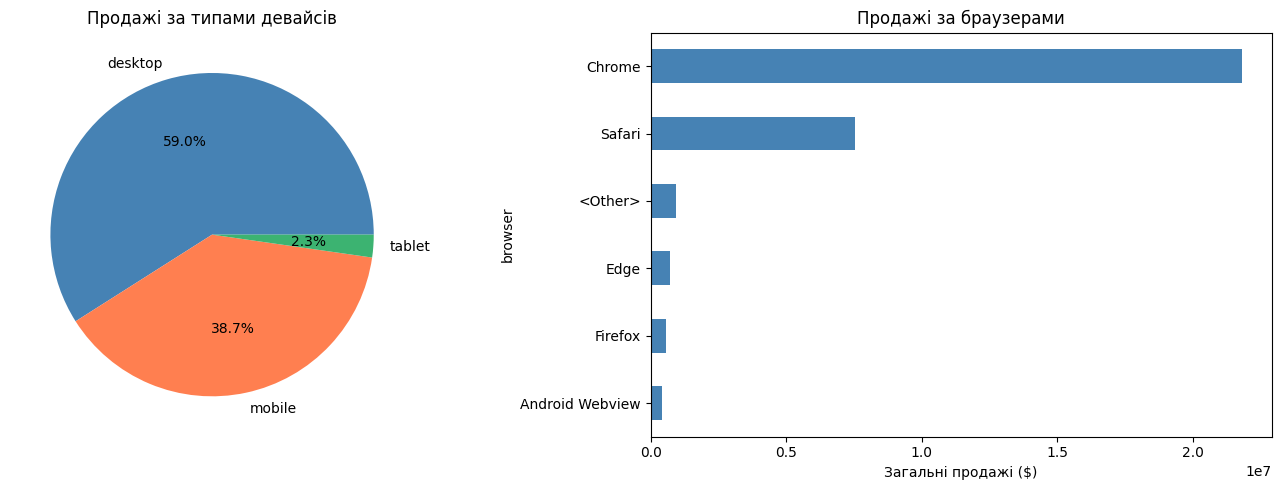

In [268]:
# Візуалізація
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(device_sales, labels=device_sales.index,
            autopct='%1.1f%%', colors=['steelblue', 'coral', 'mediumseagreen'])
axes[0].set_title('Продажі за типами девайсів')

browser_sales.sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Продажі за браузерами')
axes[1].set_xlabel('Загальні продажі ($)')

plt.tight_layout()
plt.show()

**Висновок:**
- Desktop домінує - 59% продажів
- Mobile на другому місці - 38.7%
- Tablet маргінальний - 2.3%

### 5.4 Джерела трафіку

In [269]:
# Продажі за каналами трафіку (%)
channel_sales = (df_sales.groupby('traffic_channel')['price']
                 .sum()
                 .sort_values(ascending=False))

channel_pct = (channel_sales / channel_sales.sum() * 100).round(2)
print("Продажі за каналами трафіку (%):")
print(channel_pct)

Продажі за каналами трафіку (%):
traffic_channel
Organic Search    35.76
Paid Search       26.62
Direct            23.44
Social Search      7.92
Undefined          6.26
Name: price, dtype: float64


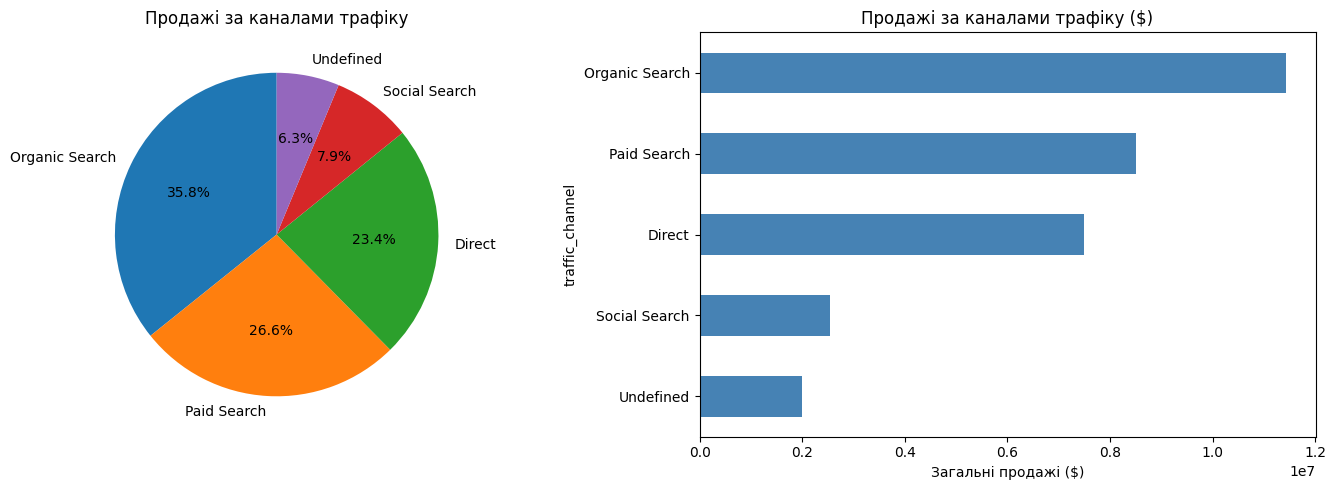

In [270]:
# Візуалізація
browser_sales = (df_sales_browser.groupby('browser')['price']
                 .sum()
                 .sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart — канали трафіку
axes[0].pie(channel_sales, labels=channel_sales.index,
            autopct='%1.1f%%', startangle=90)
axes[0].set_title('Продажі за каналами трафіку')

# Bar chart — канали трафіку в $
channel_sales.sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Продажі за каналами трафіку ($)')
axes[1].set_xlabel('Загальні продажі ($)')

plt.tight_layout()
plt.show()

**Висновок:**
- Organic Search - лідер (35.8%)
- Paid Search - другий (26.6%)
- Direct - третій (23.4%)

Інсайт: більше половини продажів приходить з безкоштовних каналів (organic + direct)

### 5.5 Зареєстровані користувачі

In [271]:
# Допоміжний датафрейм — тільки зареєстровані (унікальні користувачі!)
registered_df = (df_traffic[df_traffic['registered_user_id'].notna()]
                 .drop_duplicates(subset=['registered_user_id']))

# % підтвердили email
email_confirmed_pct = registered_df['is_email_confirmed'].mean() * 100
print(f"Підтвердили email: {email_confirmed_pct:.1f}%")

# % відписалися від розсилки
unsubscribed_pct = registered_df['is_unsubscribed'].mean() * 100
print(f"Відписалися від розсилки: {unsubscribed_pct:.1f}%")

Підтвердили email: 71.7%
Відписалися від розсилки: 16.9%


In [272]:
# Порівняння продажів: підписані vs відписані
# Беремо сесії зареєстрованих з df_traffic
subscribed_sessions = (df_traffic[df_traffic['is_unsubscribed'] == 0]
                       ['ga_session_id'])
unsubscribed_sessions = (df_traffic[df_traffic['is_unsubscribed'] == 1]
                         ['ga_session_id'])

# Фільтруємо продажі по цих сесіях
subscribed_sales = df_sales[df_sales['ga_session_id'].isin(subscribed_sessions)]
unsubscribed_sales = df_sales[df_sales['ga_session_id'].isin(unsubscribed_sessions)]

print(f"Підписані — середній чек: ${subscribed_sales['price'].mean():.2f}")
print(f"Відписані — середній чек: ${unsubscribed_sales['price'].mean():.2f}")
print(f"Підписані — кількість замовлень: {len(subscribed_sales)}")
print(f"Відписані — кількість замовлень: {len(unsubscribed_sales)}")

Підписані — середній чек: $921.51
Відписані — середній чек: $965.82
Підписані — кількість замовлень: 2334
Відписані — кількість замовлень: 447


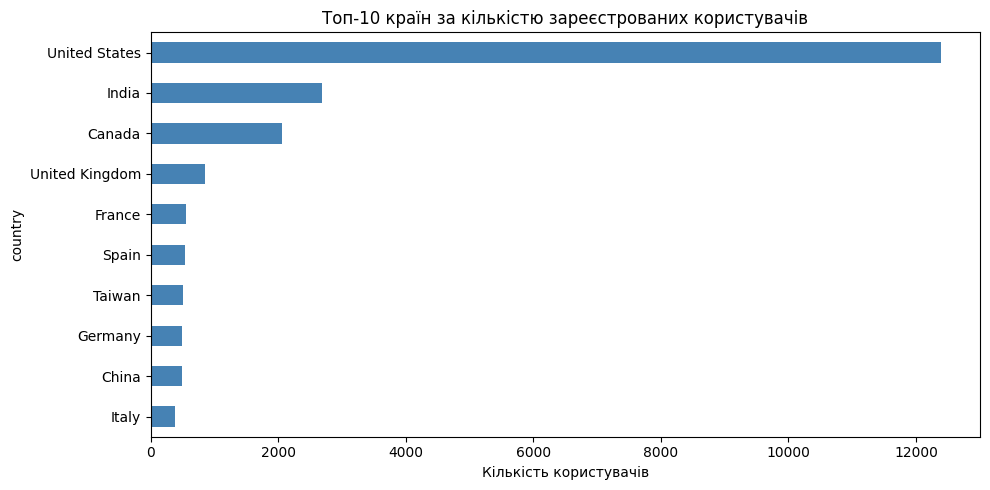

In [273]:
# Топ-10 країн за кількістю зареєстрованих користувачів
top_reg_countries = (df_traffic[df_traffic['registered_user_id'].notna()]
                     .drop_duplicates(subset=['registered_user_id'])
                     .groupby('country')['registered_user_id']
                     .count()
                     .sort_values(ascending=False)
                     .head(10))

top_reg_countries.sort_values().plot(kind='barh', figsize=(10, 5), color='steelblue')
plt.title('Топ-10 країн за кількістю зареєстрованих користувачів')
plt.xlabel('Кількість користувачів')
plt.tight_layout()
plt.show()

**Висновок:**
- 71.7% підтвердили email, це хороший показник
- 16.9% відписалися від розсилки
- Відписані мають вищий середній чек (965 дол - 921 дол), трохи парадокс виходить!

Інсайт: США домінують за кількістю зареєстрованих користувачів з величезним відривом.

### 5.6 Топ-5 країн за кількістю замовлень

In [274]:
# Топ-5 країн за кількістю замовлень
top_countries_orders = (df_sales.groupby('country')['ga_session_id']
                        .count()
                        .sort_values(ascending=False)
                        .head(5)
                        .reset_index())

top_countries_orders.columns = ['country', 'total_orders']

print("Топ-5 країн за кількістю замовлень:")
print(top_countries_orders)

Топ-5 країн за кількістю замовлень:
          country  total_orders
0   United States         14673
1           India          3029
2          Canada          2560
3  United Kingdom          1029
4          France           678


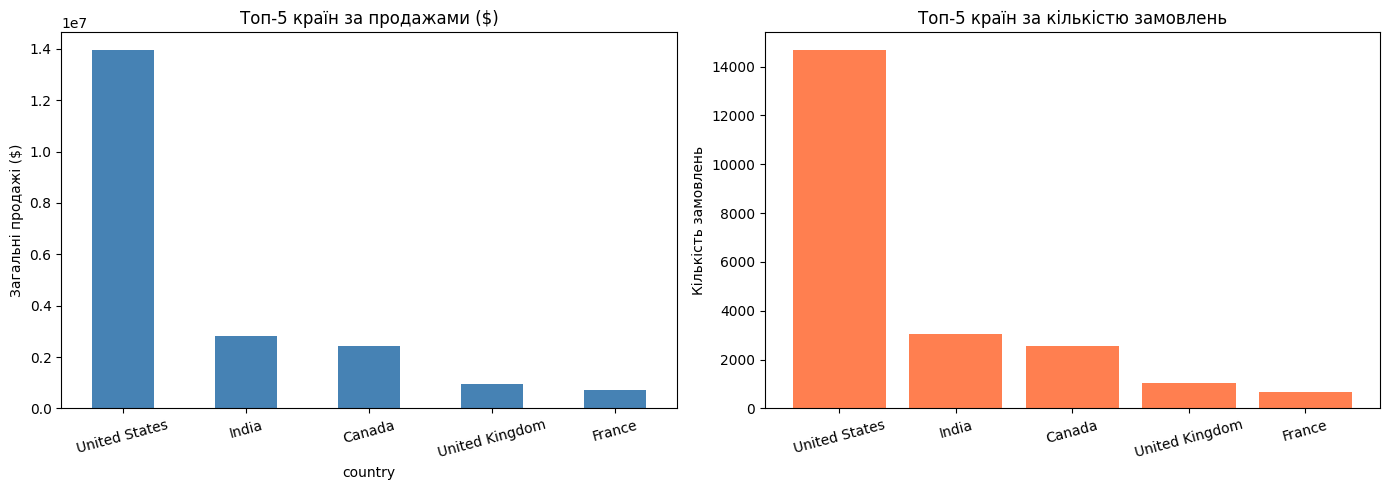

In [275]:
# Візуалізація
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# За продажами
country_sales.head(5).plot(kind='bar', y='total_sales', ax=axes[0],
                            color='steelblue', legend=False)
axes[0].set_title('Топ-5 країн за продажами ($)')
axes[0].set_ylabel('Загальні продажі ($)')
axes[0].tick_params(axis='x', rotation=15)

# За кількістю замовлень
axes[1].bar(top_countries_orders['country'],
            top_countries_orders['total_orders'], color='coral')
axes[1].set_title('Топ-5 країн за кількістю замовлень')
axes[1].set_ylabel('Кількість замовлень')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

- Рейтинг повністю збігається з рейтингом за продажами: США, Індія, Канада, UK, Франція
- США абсолютний лідер: 14,673 замовлень, що майже в 5 разів більше ніж Індія (3,029)

Інсайт: країни з найбільшими продажами = країни з найбільшою кількістю замовлень. Тобто середній чек між країнами суттєво не відрізняється

### 5.7 Додаткові інсайти

In [276]:
# Конверсія сесій у покупку по країнах (топ-10, лише країни з достатньою кількістю сесій)
total_sessions = df_traffic.groupby('country')['ga_session_id'].count()
order_sessions = df_sales.groupby('country')['ga_session_id'].count()

conversion = pd.DataFrame({'sessions': total_sessions, 'orders': order_sessions}).fillna(0)
conversion['conversion_rate_%'] = (conversion['orders'] / conversion['sessions'] * 100).round(2)

MIN_SESSIONS = 1000
big_countries = conversion[conversion['sessions'] >= MIN_SESSIONS]
print(f"Країн з {MIN_SESSIONS}+ сесій: {len(big_countries)} з {len(conversion)}")

conversion = (big_countries
              .sort_values('conversion_rate_%', ascending=False)
              .head(10)
              .reset_index())

print("Топ-10 країн за конверсією:")
print(conversion)

Країн з 1000+ сесій: 38 з 108
Топ-10 країн за конверсією:
       country  sessions  orders  conversion_rate_%
0     Pakistan      1480     184              12.43
1  Switzerland      1778     199              11.19
2       Greece      1241     137              11.04
3     Colombia      1580     174              11.01
4    Hong Kong      2067     224              10.84
5      Germany      5987     642              10.72
6    (not set)      2713     290              10.69
7  South Korea      4197     443              10.56
8        Spain      6255     658              10.52
9     Malaysia      1753     181              10.33


In [277]:
# Чи відрізняється конверсія між країнами більше, ніж випадково?
table = big_countries[['orders']].copy()
table['no_orders'] = big_countries['sessions'] - big_countries['orders']

chi2, p_value, dof, expected = stats.chi2_contingency(table.astype(float))
print(f"Хі-квадрат: p-value = {p_value:.4f}")

Хі-квадрат: p-value = 0.0270


In [278]:
# Середній чек по континентах
avg_check = (df_sales.groupby('continent')['price']
             .mean()
             .round(2)
             .sort_values(ascending=False))

print("Середній чек по континентах:")
print(avg_check)

Середній чек по континентах:
continent
(not set)    1043.20
Oceania      1003.38
Africa        977.08
Asia          956.14
Americas      952.15
Europe        947.87
Name: price, dtype: float64


In [279]:
# Продажі за браузерами
browser_sales = (df_sales_browser.groupby('browser')['price']
                 .sum()
                 .sort_values(ascending=False))

browser_pct = (browser_sales / browser_sales.sum() * 100).round(2)

print("Продажі за браузерами (%):")
print(browser_pct)

Продажі за браузерами (%):
browser
Chrome             68.27
Safari             23.54
<Other>             2.89
Edge                2.24
Firefox             1.78
Android Webview     1.29
Name: price, dtype: float64


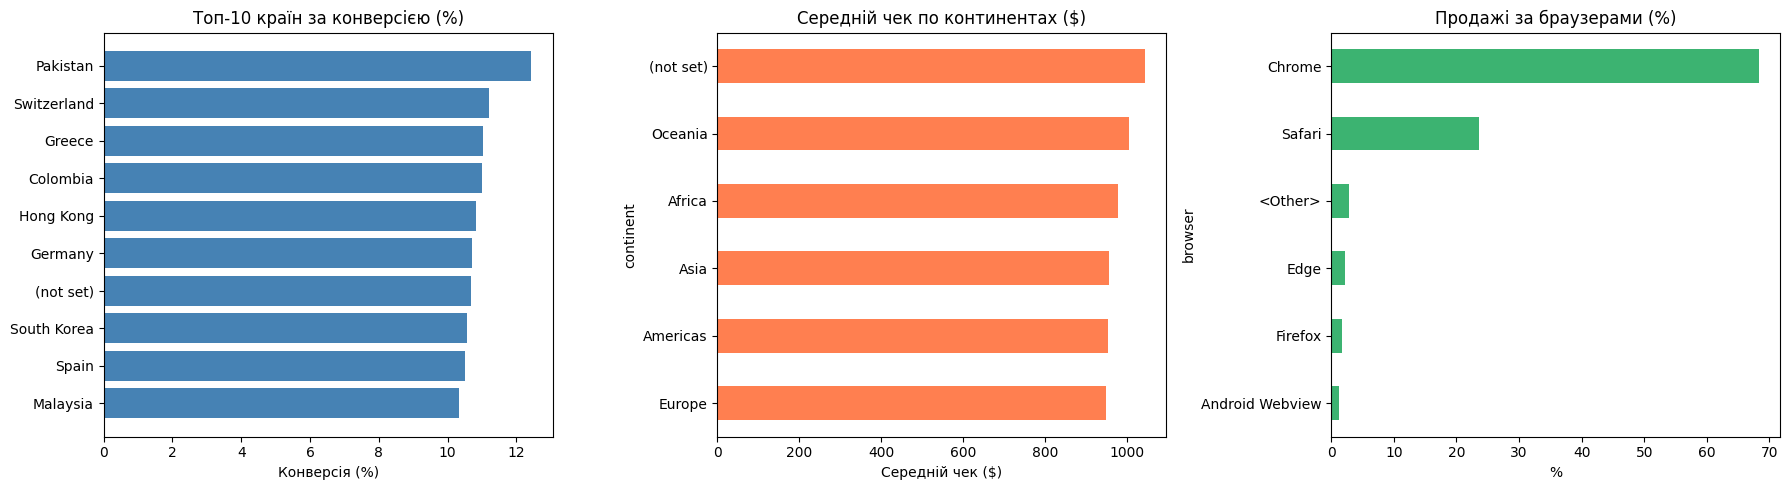

In [280]:
# Візуалізація всіх трьох інсайтів
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Конверсія
axes[0].barh(conversion['country'], conversion['conversion_rate_%'], color='steelblue')
axes[0].set_title('Топ-10 країн за конверсією (%)')
axes[0].set_xlabel('Конверсія (%)')
axes[0].invert_yaxis()

# Середній чек
avg_check.sort_values().plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Середній чек по континентах ($)')
axes[1].set_xlabel('Середній чек ($)')

# Браузери
browser_pct.sort_values().plot(kind='barh', ax=axes[2], color='mediumseagreen')
axes[2].set_title('Продажі за браузерами (%)')
axes[2].set_xlabel('%')

plt.tight_layout()
plt.show()

***Конверсія по країнах:***
- У першій версії аналізу лідерами були малі країни (Trinidad & Tobago, Jamaica, Malta, ~15–18%). Але в них мало сесій, і кілька випадкових замовлень сильно змінюють відсоток. Тому рейтинг побудовано лише для країн, де 1 000+ сесій (38 з 108).
- Серед них конверсія в більшості країн близька до середньої (10,0%): топ-10 від 10,3% до 12,4%.
- Хі-квадрат тест (p = 0,027) показує, що відмінності між країнами є, але невеликі.
- Найбільше вирізняється Пакистан: 12,4% (184 замовлення з 1 480 сесій), приблизно на 2,5 п.п. вище середнього. Оскільки порівнюється 38 країн, це може бути як реальний ефект, так і випадковий лідер. Варто подивитись, що відрізняє трафік з Пакистану (канали, девайси), і перевірити результат на новому періоді.

***Середній чек:***
- Різниця між континентами невелика: від $948 (Europe) до $1 003 (Oceania), без урахування (not set).
- Структура покупок за ціною схожа в усіх регіонах. Чи диференціює компанія ціни географічно, з цих даних сказати не можна: для цього потрібно порівнювати ціни на ті самі товари.

***Браузери:***
- Chrome (68,3%) і Safari (23,5%) разом дають 91,8% продажів.
- Ця частка, найімовірніше, відображає популярність браузерів серед відвідувачів. Але саме тому сайт і процес оформлення замовлення мають бездоганно працювати насамперед у Chrome і Safari.

## 6. Динаміка продажів

In [281]:
# Загальні продажі за кожну дату
daily_sales = (df_sales.groupby('order_date')['price']
               .sum()
               .reset_index())
daily_sales.columns = ['order_date', 'total_sales']

# Кількість сесій за кожну дату
daily_sessions = (df_traffic.groupby('order_date')['ga_session_id']
                  .count()
                  .reset_index())
daily_sessions.columns = ['order_date', 'total_sessions']

print(daily_sales.head())

  order_date  total_sales
0 2020-11-01     244292.5
1 2020-11-02     355506.8
2 2020-11-03     498979.6
3 2020-11-04     339187.1
4 2020-11-05     391276.6


### 6.1 Загальна динаміка продажів

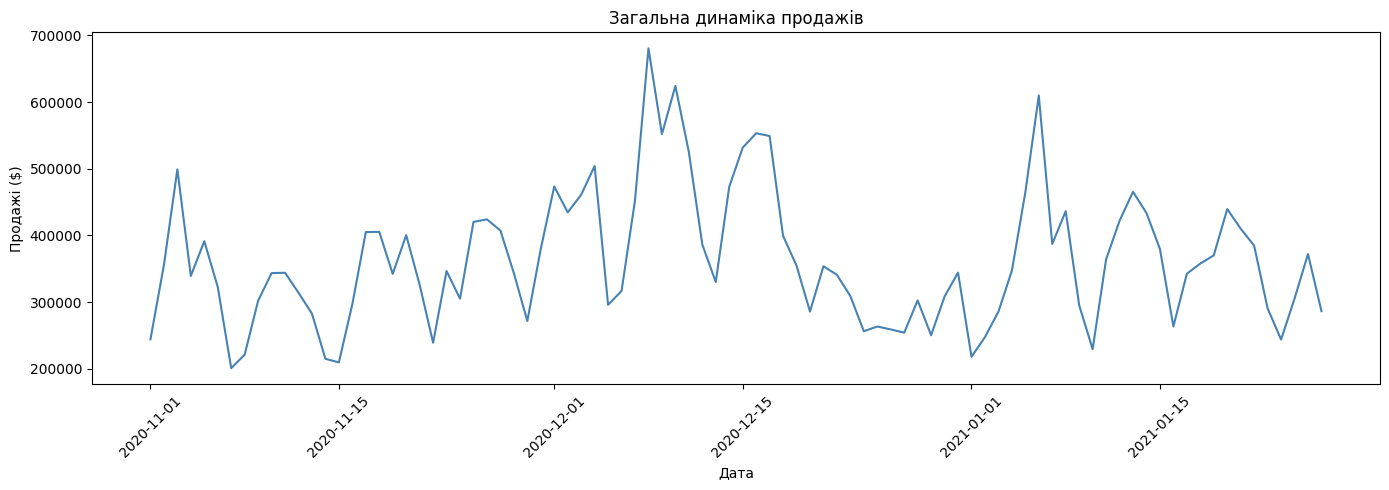

In [282]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(daily_sales['order_date'], daily_sales['total_sales'],
        color='steelblue', linewidth=1.5)
ax.set_title('Загальна динаміка продажів')
ax.set_xlabel('Дата')
ax.set_ylabel('Продажі ($)')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 6.2 Сезонність продажів

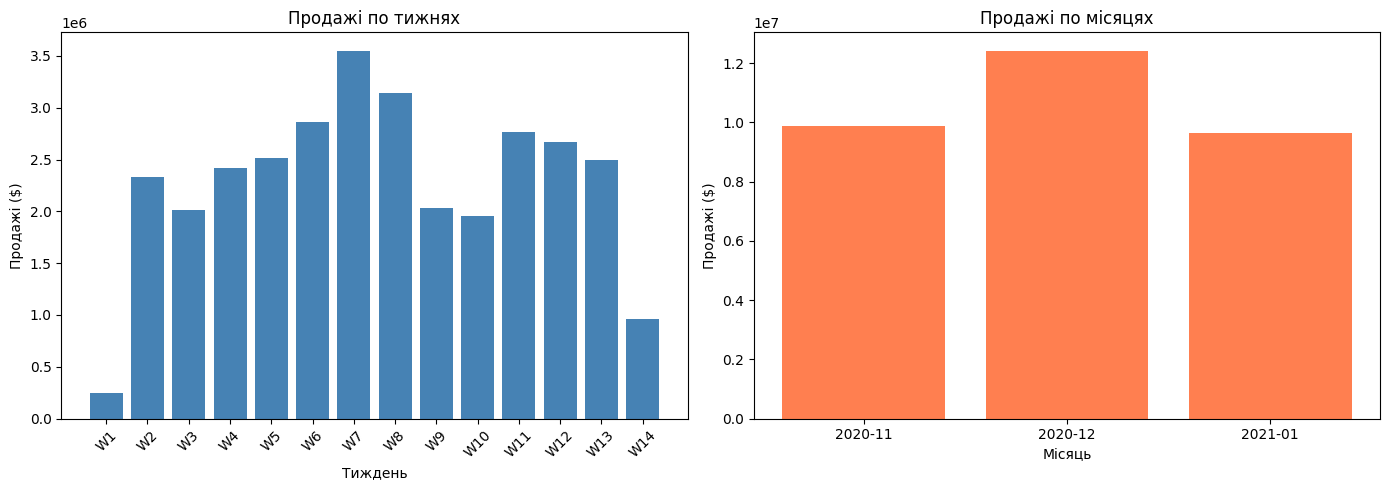

In [283]:
# Продажі по тижнях
weekly_sales = (df_sales.groupby(df_sales['order_date'].dt.to_period('W'))['price']
                .sum()
                .reset_index())
weekly_sales.columns = ['week', 'total_sales']
weekly_sales['week'] = weekly_sales['week'].astype(str)

# Продажі по місяцях
monthly_sales = (df_sales.groupby(df_sales['order_date'].dt.to_period('M'))['price']
                 .sum()
                 .reset_index())
monthly_sales.columns = ['month', 'total_sales']
monthly_sales['month'] = monthly_sales['month'].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(len(weekly_sales)), weekly_sales['total_sales'], color='steelblue')
axes[0].set_title('Продажі по тижнях')
axes[0].set_xlabel('Тиждень')
axes[0].set_ylabel('Продажі ($)')
axes[0].set_xticks(range(len(weekly_sales)))
axes[0].set_xticklabels([f'W{i+1}' for i in range(len(weekly_sales))], rotation=45)

axes[1].bar(monthly_sales['month'], monthly_sales['total_sales'], color='coral')
axes[1].set_title('Продажі по місяцях')
axes[1].set_xlabel('Місяць')
axes[1].set_ylabel('Продажі ($)')

plt.tight_layout()
plt.show()

In [284]:
# Середні продажі за день у кожному місяці
monthly_daily = (df_sales.groupby(df_sales['order_date'].dt.to_period('M'))
                 .agg(total_sales=('price', 'sum'),
                      days=('order_date', 'nunique')))

monthly_daily['sales_per_day'] = (monthly_daily['total_sales'] / monthly_daily['days']).round(0)
print(monthly_daily)

            total_sales  days  sales_per_day
order_date                                  
2020-11       9897515.0    30       329917.0
2020-12      12423439.3    31       400756.0
2021-01       9650776.8    27       357436.0


### 6.3 Динаміка продажів по континентах

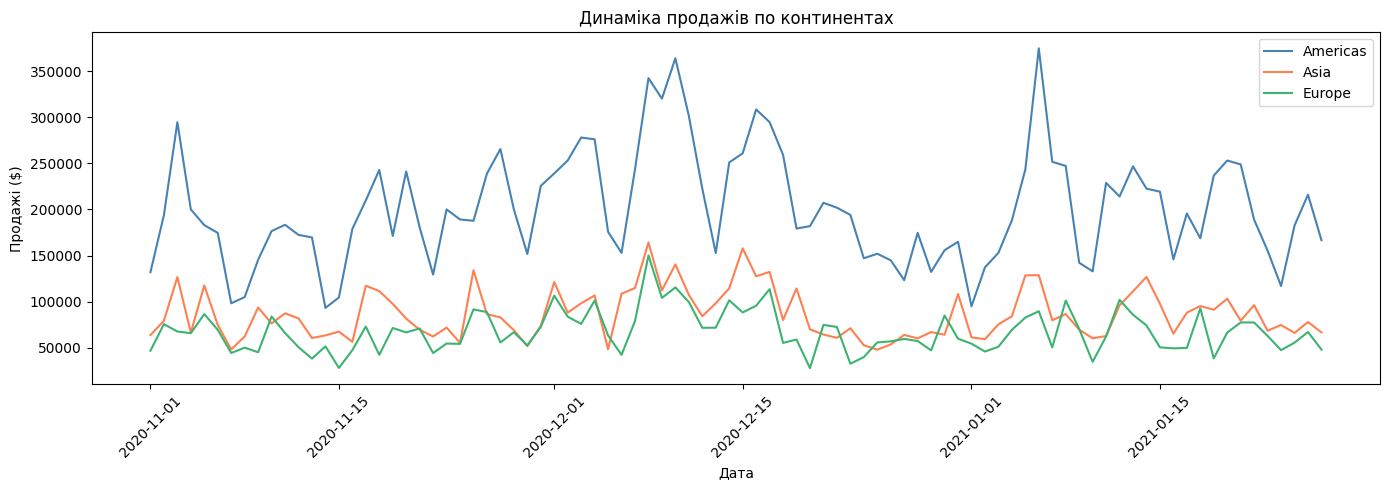

In [285]:
# Топ-3 континенти
top_continents = ['Americas', 'Asia', 'Europe']

continent_daily = (df_sales[df_sales['continent'].isin(top_continents)]
                   .groupby(['order_date', 'continent'])['price']
                   .sum()
                   .reset_index())

fig, ax = plt.subplots(figsize=(14, 5))

colors = {'Americas': 'steelblue', 'Asia': 'coral', 'Europe': 'mediumseagreen'}

for continent in top_continents:
    data = continent_daily[continent_daily['continent'] == continent]
    ax.plot(data['order_date'], data['price'],
            label=continent, color=colors[continent], linewidth=1.5)

ax.set_title('Динаміка продажів по континентах')
ax.set_xlabel('Дата')
ax.set_ylabel('Продажі ($)')
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 6.4 Динаміка продажів по каналах трафіку

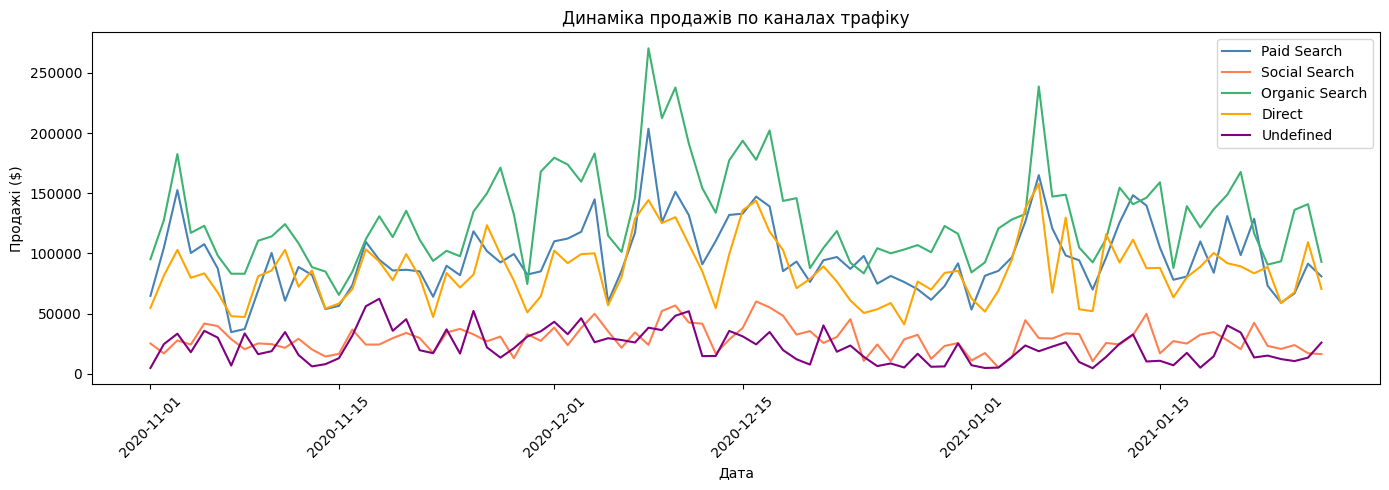

In [286]:
channel_daily = (df_sales.groupby(['order_date', 'traffic_channel'])['price']
                 .sum()
                 .reset_index())

channels = df_sales['traffic_channel'].unique()
colors_ch = ['steelblue', 'coral', 'mediumseagreen', 'orange', 'purple']

fig, ax = plt.subplots(figsize=(14, 5))

for i, channel in enumerate(channels):
    data = channel_daily[channel_daily['traffic_channel'] == channel]
    ax.plot(data['order_date'], data['price'],
            label=channel, color=colors_ch[i], linewidth=1.5)

ax.set_title('Динаміка продажів по каналах трафіку')
ax.set_xlabel('Дата')
ax.set_ylabel('Продажі ($)')
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 6.5 Динаміка продажів по типах девайсів

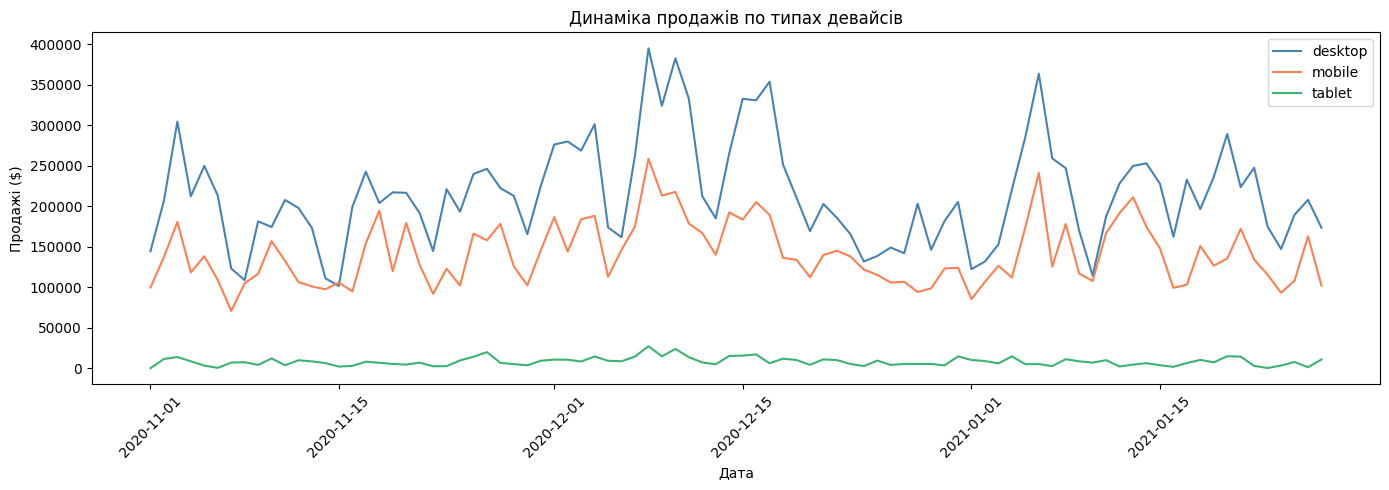

In [287]:
device_daily = (df_sales.groupby(['order_date', 'device'])['price']
                .sum()
                .reset_index())

devices = df_sales['device'].unique()
colors_dev = {'desktop': 'steelblue', 'mobile': 'coral', 'tablet': 'mediumseagreen'}

fig, ax = plt.subplots(figsize=(14, 5))

for device in devices:
    data = device_daily[device_daily['device'] == device]
    ax.plot(data['order_date'], data['price'],
            label=device, color=colors_dev[device], linewidth=1.5)

ax.set_title('Динаміка продажів по типах девайсів')
ax.set_xlabel('Дата')
ax.set_ylabel('Продажі ($)')
ax.legend()
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**6.1 Загальна динаміка**
- Продажі коливаються приблизно від 200 тис. дол. до 680 тис.дол. на день.
- Помітні регулярні піки та спади, схожі на тижневу циклічність.
- Найбільший пік - середина грудня (680 тис.дол. за день).

**6.2 Сезонність**
- Місяці мають різну кількість днів з даними: таблиця замовлень закінчується 27.01, тому в січні лише 27 днів. Порівнюємо середні продажі за день, а не суми за місяць.
- Грудень - найсильніший місяць: майже 401 тис. дол за день, на 21% більше, ніж у листопаді (330 тис.), і на 12% більше, ніж у січні (357 тис.).
- Пік - тижні W7–W8 (7–20 грудня), найімовірніше, передноворічні покупки.
- Січень після свят не повертається до рівня листопада, а лишається вищим на ~8%.
- W1 і W14 - неповні тижні, тому значення в них менші.

**6.3 Континенти**
- Americas стабільно домінує протягом усього періоду.
- Asia та Europe мають схожу динаміку.
- Усі три континенти мають спільний пік у середині грудня.

**6.4 Канали трафіку**
- Organic Search лідирує весь період.
- Paid Search на другому місці, але нестабільний, з різкими піками.
- Direct рівномірний, без різких коливань.
- Social Search та Undefined мають мінімальний внесок.

**6.5 Девайси**
- Desktop стабільно приносить приблизно в 1,5 раза більше продажів, ніж Mobile (59% проти 39%).
- Обидва мають синхронні піки: попит змінюється однаково незалежно від девайсу.
- Tablet майже непомітний на графіку.

### 6.6 Продажі по днях тижня

day_of_week
Monday       4636290.4
Tuesday      5457515.9
Wednesday    5466542.9
Thursday     4936935.6
Friday       4523067.2
Saturday     3477990.9
Sunday       3473388.2
Name: price, dtype: float64


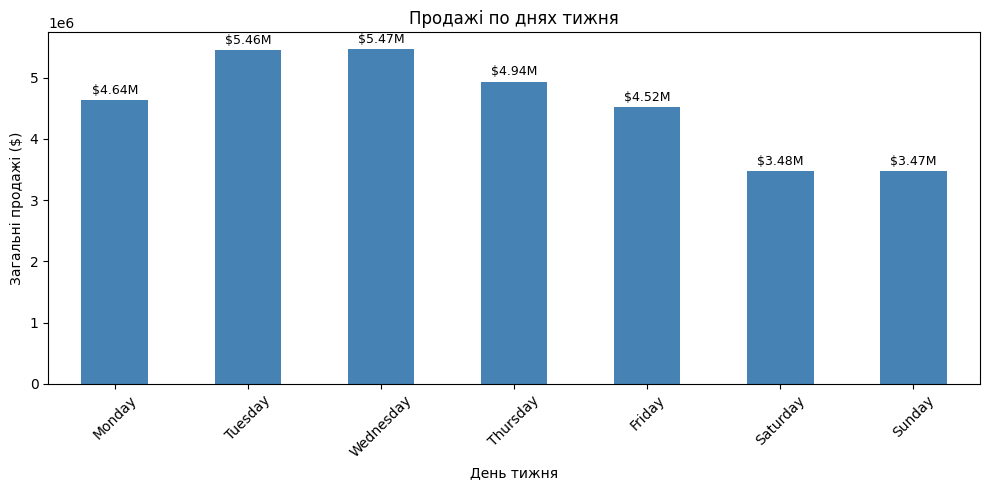

In [288]:
# Продажі по днях тижня
df_sales['day_of_week'] = df_sales['order_date'].dt.day_name()

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_sales = (df_sales.groupby('day_of_week')['price']
             .sum()
             .reindex(dow_order))

print(dow_sales.round(2))

dow_sales.plot(kind='bar', figsize=(10, 5), color='steelblue')
plt.title('Продажі по днях тижня')
plt.xlabel('День тижня')
plt.ylabel('Загальні продажі ($)')
plt.xticks(rotation=45)

# Додаємо числа на бари
for i, val in enumerate(dow_sales):
    plt.text(i, val + 50000, f'${val/1e6:.2f}M',
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

- Вівторок і середа - найсильніші дні (~ 5,46 млн і ~ 5,47 млн за весь період).
- Вихідні помітно слабші: субота і неділя ~ 3,47–3,48 млн. У середньому день вихідних приносить приблизно на 30% менше продажів, ніж будній день.
- Найімовірніше, покупці меблів частіше оформлюють замовлення в робочі дні. Перевірити це можна, порівнявши трафік і конверсію за днями тижня: менше продажів у вихідні може означати як менше відвідувачів, так і нижчу конверсію.

## 7. Зведені таблиці (Pivot Tables)

### 7.1 Кількість сесій: канали трафіку × типи девайсів

In [289]:
# Фільтруємо невідомі значення
pivot_sessions = pd.pivot_table(
    df_traffic[
        (df_traffic['traffic_channel'] != 'Undefined') &
        (df_traffic['device'].notna())
    ],
    values='ga_session_id',
    index='traffic_channel',
    columns='device',
    aggfunc='count'
).round(0).astype(int)

# Додаємо колонку Total
pivot_sessions['Total'] = pivot_sessions.sum(axis=1)

# Сортуємо за Total
pivot_sessions = pivot_sessions.sort_values('Total', ascending=False)

print(pivot_sessions)

device           desktop  mobile  tablet   Total
traffic_channel                                 
Organic Search     69857   47161    2669  119687
Paid Search        53091   35579    2060   90730
Direct             45940   30493    1745   78178
Social Search      15652   10549     615   26816


- Organic Search домінує по всіх девайсах, 124425 сесій загально
- Desktop лідирує в усіх каналах без винятку
- Tablet скрізь мінімальний, менше 3% від загального трафіку
- Paid Search на desktop (55,167) найбільш окупний канал для таргетингу

### 7.2 Продажі: топ-10 категорій × топ-5 країн

In [290]:
# Визначаємо топ-10 категорій та топ-5 країн
top_10_cat = (df_sales.groupby('product_category')['price']
              .sum()
              .sort_values(ascending=False)
              .head(10)
              .index.tolist())

top_5_countries = (df_sales.groupby('country')['price']
                   .sum()
                   .sort_values(ascending=False)
                   .head(5)
                   .index.tolist())

# Фільтруємо датафрейм
df_pivot = df_sales[
    (df_sales['product_category'].isin(top_10_cat)) &
    (df_sales['country'].isin(top_5_countries))
]

# Зведена таблиця
pivot_sales = pd.pivot_table(
    df_pivot,
    values='price',
    index='product_category',
    columns='country',
    aggfunc='sum'
).round(0).astype(int)

# Додаємо колонку Total і сортуємо
pivot_sales['Total'] = pivot_sales.sum(axis=1)
pivot_sales = pivot_sales.sort_values('Total', ascending=False)

print(pivot_sales)

country                           Canada  France   India  United Kingdom  \
product_category                                                           
Sofas & armchairs                 692428  187735  788430          234812   
Chairs                            417741  134029  544309          188519   
Beds                              354772  116414  358320          133816   
Bookcases & shelving units        278982   73830  364507          113988   
Cabinets & cupboards              181802   59102  191888           71684   
Outdoor furniture                 185323   40486  162289           57002   
Tables & desks                    132678   42299  186158           49374   
Chests of drawers & drawer units   71952   21544   73111           36784   
Bar furniture                      51724   11199   57657           22103   
Children's furniture               30264   14258   39177           13348   

country                           United States    Total  
product_category            

- США домінують в кожній категорії без винятку
- Sofas & armchairs - лідер у всіх топ-5 країнах
- Індія на другому місці майже в усіх категоріях
- Children's furniture - найслабша категорія у всіх країнах

### 7.3 Продажі: девайси × канали трафіку

In [291]:
pivot_device_channel = pd.pivot_table(
    df_sales[df_sales['traffic_channel'] != 'Undefined'],
    values='price',
    index='device',
    columns='traffic_channel',
    aggfunc='sum'
).round(0).astype(int)

pivot_device_channel['Total'] = pivot_device_channel.sum(axis=1)
pivot_device_channel = pivot_device_channel.sort_values('Total', ascending=False)

print(pivot_device_channel)

traffic_channel   Direct  Organic Search  Paid Search  Social Search     Total
device                                                                        
desktop          4472609         6794108      4976978        1447385  17691080
mobile           2875318         4408875      3330033        1006707  11620933
tablet            146996          230169       204039          78014    659218


- Desktop + Organic Search - найбільша комбінація 6.79 млн дол.
- Desktop генерує більше половини продажів у кожному каналі
- Mobile + Organic Search 4.41 млн дол. - другий за силою сегмент

### 7.4 Середній чек: категорії × девайси

In [292]:
pivot_avg_check = pd.pivot_table(
    df_sales,
    values='price',
    index='product_category',
    columns='device',
    aggfunc='mean'
).round(2)

pivot_avg_check['Total_avg'] = pivot_avg_check.mean(axis=1).round(2)
pivot_avg_check = pivot_avg_check.sort_values('Total_avg', ascending=False)

print(pivot_avg_check)

device                                desktop   mobile   tablet  Total_avg
product_category                                                          
Sofas & armchairs                     1939.86  1965.71  1954.04    1953.20
Beds                                  1708.85  1646.09  1612.55    1655.83
Chairs                                1058.55   984.08  1186.81    1076.48
Cabinets & cupboards                  1001.67  1006.66  1201.67    1070.00
Outdoor furniture                      958.85   961.09  1023.43     981.12
Sideboards, buffets & console tables   972.04   945.57   780.00     899.20
Room dividers                          806.28   835.44   978.00     873.24
Bar furniture                          668.83   686.38   583.08     646.10
Chests of drawers & drawer units       627.39   617.69   668.26     637.78
Tables & desks                         610.18   610.24   551.22     590.55
Café furniture                         386.24   373.23   725.00     494.82
Bookcases & shelving unit

- Sofas & armchairs мають найвищий середній чек ~1,953 дол. на всіх девайсах
- Children's furniture - найнижчий середній чек 288 дол.
- Різниця між desktop та mobile мінімальна, девайс не впливає на суму покупки
- Tablet іноді має вищий середній чек ніж desktop, цікавий результат

## 8. Статистичний аналіз — Кореляції

### 8.1 Кореляція між кількістю сесій та продажами по датах

In [293]:
daily_sales = (df_sales.groupby('order_date')['price']
               .sum()
               .reset_index())
daily_sales.columns = ['order_date', 'total_sales']

daily_sessions = (df_traffic.groupby('order_date')['ga_session_id']
                  .count()
                  .reset_index())
daily_sessions.columns = ['order_date', 'total_sessions']

# Обʼєднуємо
daily = daily_sessions.merge(daily_sales, on='order_date', how='left')
daily['total_sales'] = daily['total_sales'].fillna(0)


print(daily.head())

  order_date  total_sessions  total_sales
0 2020-11-01            2576     244292.5
1 2020-11-02            3599     355506.8
2 2020-11-03            5173     498979.6
3 2020-11-04            4184     339187.1
4 2020-11-05            3743     391276.6


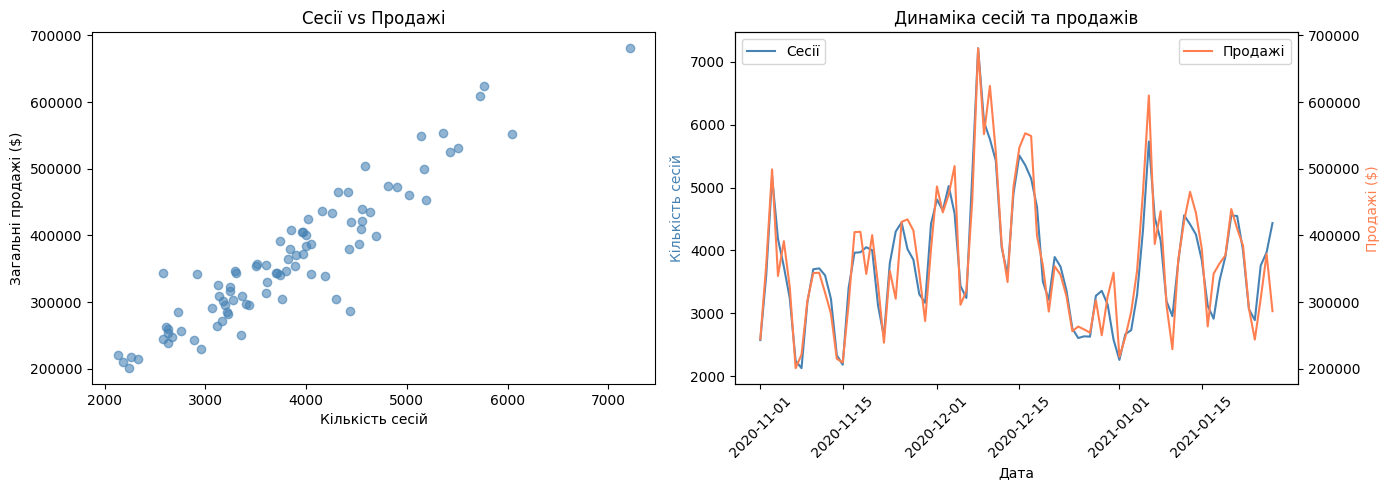

In [294]:
# Візуалізація взаємозвʼязку
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(daily['total_sessions'], daily['total_sales'],
                alpha=0.6, color='steelblue')
axes[0].set_title('Сесії vs Продажі')
axes[0].set_xlabel('Кількість сесій')
axes[0].set_ylabel('Загальні продажі ($)')

# Динаміка обох метрик
ax2 = axes[1].twinx()
axes[1].plot(daily['order_date'], daily['total_sessions'],
             color='steelblue', label='Сесії', linewidth=1.5)
ax2.plot(daily['order_date'], daily['total_sales'],
         color='coral', label='Продажі', linewidth=1.5)
axes[1].set_title('Динаміка сесій та продажів')
axes[1].set_xlabel('Дата')
axes[1].set_ylabel('Кількість сесій', color='steelblue')
ax2.set_ylabel('Продажі ($)', color='coral')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [295]:
# Коефіцієнт кореляції Пірсона
corr, pvalue = stats.pearsonr(daily['total_sessions'], daily['total_sales'])
print(f"Коефіцієнт кореляції Пірсона: {corr:.4f}")
print(f"P-value: {pvalue:.25f}")
print(f"Статистично значущий: {'Так' if pvalue < 0.05 else 'Ні'}")

Коефіцієнт кореляції Пірсона: 0.9313
P-value: 0.0000000000000000000000000
Статистично значущий: Так


- Сильна позитивна кореляція, більше сесій = більше продажів
- На scatter plot видно кілька викидів. Дні зі значною кількістю сесій (2500-4000+), але нульовими продажами. Це реальні дні без жодної покупки, а не помилка в даних. саме ці точки і знижують кореляцію 0.79
- На графіку динаміки два рядки майже повністю збігаються, але під кінець можемо бачити провал у продажах при збереженні відвідуваності сайту.


Трафік є надійним предиктором продажів, інвестиції в залучення відвідувачів прямо впливають на виручку

### 8.2 Кореляція продажів між континентами

In [296]:
# Топ-3 континенти по датах
top_3_continents = ['Americas', 'Asia', 'Europe']

continent_daily = (df_sales[df_sales['continent'].isin(top_3_continents)]
                   .groupby(['order_date', 'continent'])['price']
                   .sum()
                   .unstack()
                   .fillna(0))

print(continent_daily.head())

continent   Americas      Asia   Europe
order_date                             
2020-11-01  132002.5   63823.0  46908.0
2020-11-02  193861.0   79370.0  75710.8
2020-11-03  294529.8  126737.8  67692.0
2020-11-04  200009.5   66602.0  65915.0
2020-11-05  182988.2  117608.4  86540.0


Матриця кореляцій:
continent  Americas    Asia  Europe
continent                          
Americas     1.0000  0.6923  0.6695
Asia         0.6923  1.0000  0.6678
Europe       0.6695  0.6678  1.0000


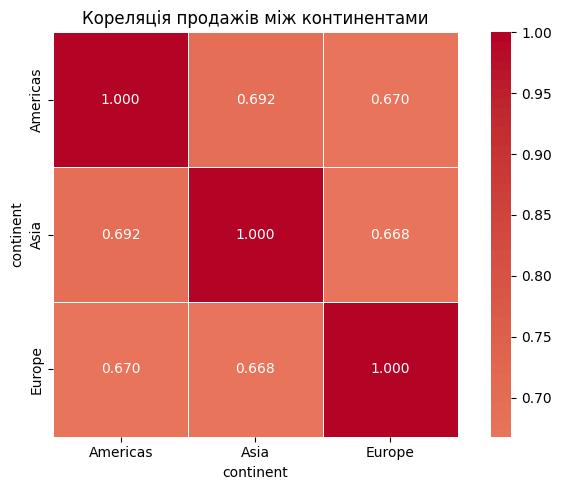

In [297]:
# Матриця кореляцій
corr_matrix = continent_daily.corr()
print("Матриця кореляцій:")
print(corr_matrix.round(4))

# Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.3f',
            cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Кореляція продажів між континентами')
plt.tight_layout()
plt.show()

In [298]:
# Статистична значущість для кожної пари
pairs = [('Americas', 'Asia'), ('Americas', 'Europe'), ('Asia', 'Europe')]

for c1, c2 in pairs:
    corr, pvalue = stats.pearsonr(continent_daily[c1], continent_daily[c2])
    print(f"{c1} vs {c2}: r={corr:.4f}, p={pvalue:.4f}, "
          f"значущий: {'Так' if pvalue < 0.05 else 'Ні'}")

Americas vs Asia: r=0.6923, p=0.0000, значущий: Так
Americas vs Europe: r=0.6695, p=0.0000, значущий: Так
Asia vs Europe: r=0.6678, p=0.0000, значущий: Так


- Всі три пари мають сильну кореляцію: Americas-Asia (0.692), Americas-Europe (0.670), Asia-Europe (0.668)
- Всі значущі статистично


Продажі на різних континентах рухаються синхронно, є спільний глобальний фактор (сезонність, маркетингові кампанії)

### 8.3 Кореляція між каналами трафіку

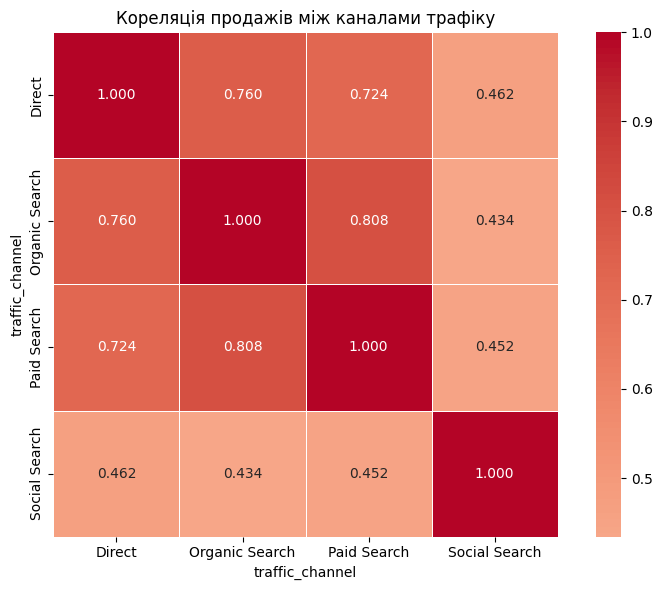

In [299]:
# Продажі по каналах по датах
channel_daily = (df_sales[df_sales['traffic_channel'] != 'Undefined']
                 .groupby(['order_date', 'traffic_channel'])['price']
                 .sum()
                 .unstack()
                 .fillna(0))

# Матриця кореляцій
corr_channels = channel_daily.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_channels, annot=True, fmt='.3f',
            cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Кореляція продажів між каналами трафіку')
plt.tight_layout()
plt.show()

In [300]:
# Статистична значущість
from itertools import combinations

channels = channel_daily.columns.tolist()

for c1, c2 in combinations(channels, 2):
    corr, pvalue = stats.pearsonr(channel_daily[c1], channel_daily[c2])
    print(f"{c1} vs {c2}: r={corr:.4f}, p={pvalue:.4f}, "
          f"значущий: {'Так' if pvalue < 0.05 else 'Ні'}")

Direct vs Organic Search: r=0.7599, p=0.0000, значущий: Так
Direct vs Paid Search: r=0.7243, p=0.0000, значущий: Так
Direct vs Social Search: r=0.4619, p=0.0000, значущий: Так
Organic Search vs Paid Search: r=0.8082, p=0.0000, значущий: Так
Organic Search vs Social Search: r=0.4344, p=0.0000, значущий: Так
Paid Search vs Social Search: r=0.4523, p=0.0000, значущий: Так


- Найсильніша пара: Organic Search vs Paid Search (0.808)
- Social Search має найслабші кореляції з усіма (~0.43-0.46)

Organic, Paid та Direct ростуть і падають разом — вони залежать від одного попиту. Social Search живе за своїми законами

### 8.4 Кореляція між топ-5 категоріями товарів

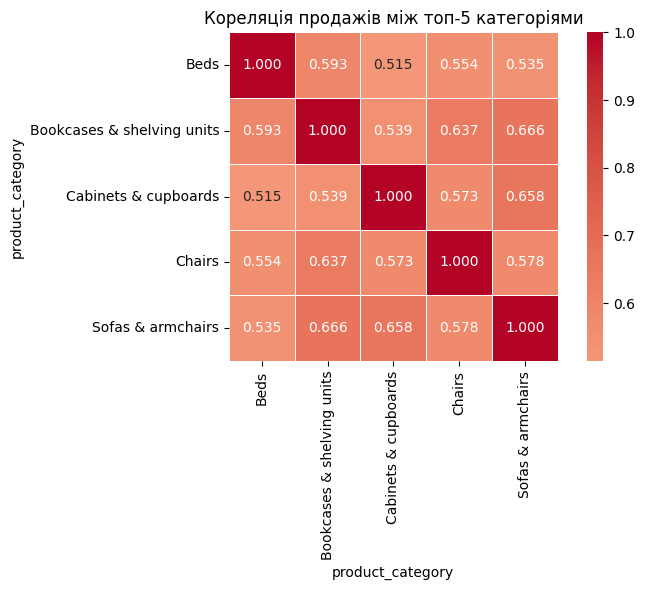

In [301]:
# Топ-5 категорій
top_5_cat = (df_sales.groupby('product_category')['price']
             .sum()
             .sort_values(ascending=False)
             .head(5)
             .index.tolist())

# Продажі по категоріях по датах
cat_daily = (df_sales[df_sales['product_category'].isin(top_5_cat)]
             .groupby(['order_date', 'product_category'])['price']
             .sum()
             .unstack()
             .fillna(0))

# Матриця кореляцій
corr_cat = cat_daily.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_cat, annot=True, fmt='.3f',
            cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Кореляція продажів між топ-5 категоріями')
plt.tight_layout()
plt.show()

In [302]:
# Статистична значущість
for c1, c2 in combinations(top_5_cat, 2):
    corr, pvalue = stats.pearsonr(cat_daily[c1], cat_daily[c2])
    print(f"{c1} vs {c2}: r={corr:.4f}, p={pvalue:.4f}, "
          f"значущий: {'Так' if pvalue < 0.05 else 'Ні'}")


Sofas & armchairs vs Chairs: r=0.5782, p=0.0000, значущий: Так
Sofas & armchairs vs Beds: r=0.5354, p=0.0000, значущий: Так
Sofas & armchairs vs Bookcases & shelving units: r=0.6662, p=0.0000, значущий: Так
Sofas & armchairs vs Cabinets & cupboards: r=0.6576, p=0.0000, значущий: Так
Chairs vs Beds: r=0.5545, p=0.0000, значущий: Так
Chairs vs Bookcases & shelving units: r=0.6371, p=0.0000, значущий: Так
Chairs vs Cabinets & cupboards: r=0.5729, p=0.0000, значущий: Так
Beds vs Bookcases & shelving units: r=0.5929, p=0.0000, значущий: Так
Beds vs Cabinets & cupboards: r=0.5146, p=0.0000, значущий: Так
Bookcases & shelving units vs Cabinets & cupboards: r=0.5394, p=0.0000, значущий: Так


In [303]:
# Скільки товарів у одному замовленні (сесії)?
items_per_order = df_sales.groupby('ga_session_id')['item_id'].count()
print(items_per_order.value_counts())

item_id
1    33538
Name: count, dtype: Int64


- Всі пари мають помірну кореляцію (0.51-0.67)
- Найсильніша Bookcases & Chairs (0.637) та Sofas & Bookcases (0.666)


## 9. Статистичний аналіз - Тести на відмінності між групами

### Перед кожним тестом треба перевірити розподіл даних:
- Якщо дані нормально розподілені → параметричні тести (t-test)
- Якщо дані не нормальні → непараметричні тести (Mann-Whitney, Kruskal-Wallis)

Для перевірки нормальності використовуємо тест Шапіро-Вілка:
- `p > 0.05` → нормальний розподіл
- `p < 0.05` → не нормальний розподіл

### 9.1 Продажі зареєстрованих vs незареєстрованих користувачів

In [304]:
# Створюємо вибірки
registered_sessions = (df_traffic[df_traffic['registered_user_id'].notna()]
                       ['ga_session_id'])
unregistered_sessions = (df_traffic[df_traffic['registered_user_id'].isna()]
                         ['ga_session_id'])

# Продажі по кожній групі
registered_sales = (df_sales[df_sales['ga_session_id']
                    .isin(registered_sessions)]['price'])
unregistered_sales = (df_sales[df_sales['ga_session_id']
                      .isin(unregistered_sessions)]['price'])

print(f"Зареєстровані — кількість покупок: {len(registered_sales)}")
print(f"Незареєстровані — кількість покупок: {len(unregistered_sales)}")
print(f"Зареєстровані — середній чек: ${registered_sales.mean():.2f}")
print(f"Незареєстровані — середній чек: ${unregistered_sales.mean():.2f}")

Зареєстровані — кількість покупок: 2781
Незареєстровані — кількість покупок: 30757
Зареєстровані — середній чек: $928.63
Незареєстровані — середній чек: $955.53


In [305]:
# Перевірка нормальності (Шапіро-Вілка — на підвибірці бо датасет великий)
sample_reg = registered_sales.sample(min(500, len(registered_sales)), random_state=42)
sample_unreg = unregistered_sales.sample(min(500, len(unregistered_sales)), random_state=42)

stat1, p1 = stats.shapiro(sample_reg)
stat2, p2 = stats.shapiro(sample_unreg)

print(f"Шапіро-Вілк (зареєстровані): p={p1:.4f} → "
      f"{'нормальний' if p1 > 0.05 else 'не нормальний'}")
print(f"Шапіро-Вілк (незареєстровані): p={p2:.4f} → "
      f"{'нормальний' if p2 > 0.05 else 'не нормальний'}")

Шапіро-Вілк (зареєстровані): p=0.0000 → не нормальний
Шапіро-Вілк (незареєстровані): p=0.0000 → не нормальний


/tmp/ipykernel_4464/3744045340.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([registered_sales, unregistered_sales],


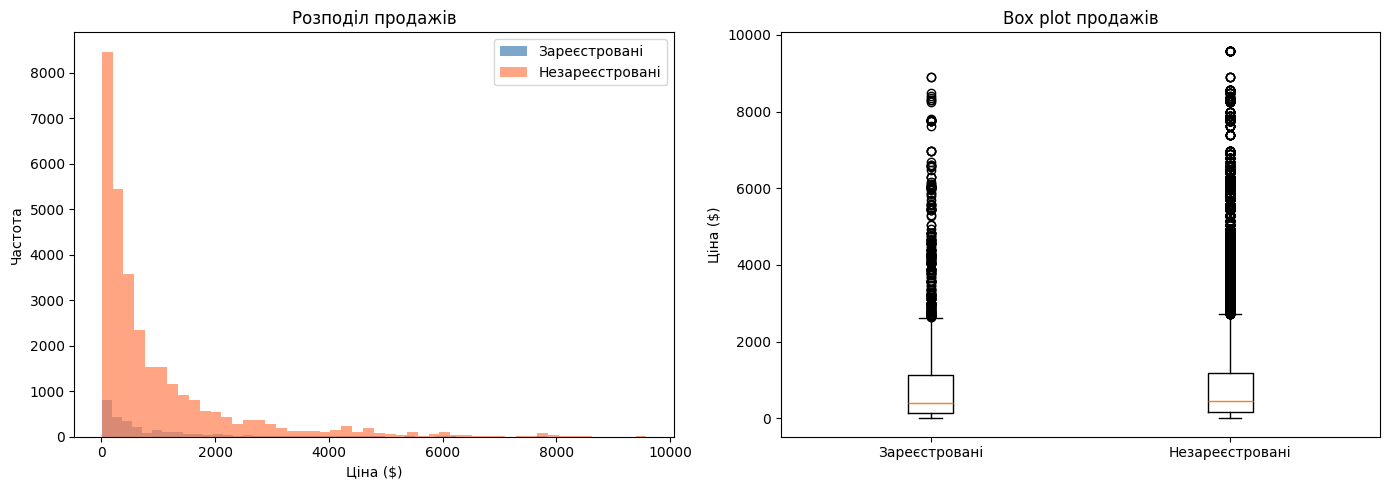

In [306]:
# Візуалізація розподілів
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(registered_sales, bins=50, color='steelblue', alpha=0.7,
             label='Зареєстровані')
axes[0].hist(unregistered_sales, bins=50, color='coral', alpha=0.7,
             label='Незареєстровані')
axes[0].set_title('Розподіл продажів')
axes[0].set_xlabel('Ціна ($)')
axes[0].set_ylabel('Частота')
axes[0].legend()

# Box plot
axes[1].boxplot([registered_sales, unregistered_sales],
                labels=['Зареєстровані', 'Незареєстровані'])
axes[1].set_title('Box plot продажів')
axes[1].set_ylabel('Ціна ($)')

plt.tight_layout()
plt.show()

In [307]:
# Mann-Whitney U тест (бо розподіл не нормальний)
stat, pvalue = stats.mannwhitneyu(registered_sales, unregistered_sales,
                                   alternative='two-sided')
print(f"Mann-Whitney U тест:")
print(f"Статистика: {stat:.2f}")
print(f"P-value: {pvalue:.4f}")
print(f"Висновок: {'Є статистично значуща відмінність' if pvalue < 0.05 else 'Відмінності незначущі'}")

Mann-Whitney U тест:
Статистика: 41771375.00
P-value: 0.0416
Висновок: Є статистично значуща відмінність


- Обидва розподіли не нормальні (Шапіро p < 0,001), тому використано Mann-Whitney.
- Середній чек незареєстрованих 956 дол., зареєстрованих 929 дол. (різниця ~3%).
- p = 0,042, формально нижче 0,05, але різниця невелика, а результат на межі значущості. З урахуванням кількості перевірок у ноутбуці його варто сприймати як гіпотезу.
- Можливі пояснення (знижки для зареєстрованих, інші товари) даними не перевірялись.

### 9.2 Кількість сесій за каналами трафіку (Kruskal-Wallis)

In [308]:
# Створюємо групи — сесії по датах для кожного каналу
channel_daily = (df_traffic[df_traffic['traffic_channel'] != 'Undefined']
                 .groupby(['order_date', 'traffic_channel'])['ga_session_id']
                 .count()
                 .reset_index())

groups = [group['ga_session_id'].values
          for _, group in channel_daily.groupby('traffic_channel')]

channel_names = channel_daily['traffic_channel'].unique()
print("Середня кількість сесій по каналах:")
for name, group in zip(channel_names,groups):
    print(f"{name}: {group.mean():.1f}")

Середня кількість сесій по каналах:
Direct: 888.4
Organic Search: 1360.1
Paid Search: 1031.0
Social Search: 304.7


In [309]:
# Kruskal-Wallis тест
stat, pvalue = stats.kruskal(*groups)
print(f"\nKruskal-Wallis тест:")
print(f"Статистика: {stat:.2f}")
print(f"P-value: {pvalue:.4f}")
print(f"Висновок: {'Є статистично значущі відмінності між каналами' if pvalue < 0.05 else 'Відмінності незначущі'}")


Kruskal-Wallis тест:
Статистика: 248.60
P-value: 0.0000
Висновок: Є статистично значущі відмінності між каналами


- Organic Search лідирує (1352 сесій/день), Social Search найменший (303)
- P-value = 0.0000  відмінності статистично значущі


Канали суттєво відрізняються за обсягом трафіку, Organic Search у 4.5 рази потужніший за Social Search

### 9.3 Частка органічного трафіку: Європа vs Америка (Z-test)

In [310]:
# Рахуємо частку органічного трафіку
europe = df_traffic[df_traffic['continent'] == 'Europe']
americas = df_traffic[df_traffic['continent'] == 'Americas']

# Кількість органічних сесій та загальна кількість
europe_organic = (europe['traffic_channel'] == 'Organic Search').sum()
americas_organic = (americas['traffic_channel'] == 'Organic Search').sum()

europe_total = len(europe)
americas_total = len(americas)

europe_rate = europe_organic / europe_total
americas_rate = americas_organic / americas_total

print(f"Європа — частка органічного трафіку: {europe_rate:.4f} ({europe_rate*100:.2f}%)")
print(f"Америка — частка органічного трафіку: {americas_rate:.4f} ({americas_rate*100:.2f}%)")

Європа — частка органічного трафіку: 0.3559 (35.59%)
Америка — частка органічного трафіку: 0.3558 (35.58%)


In [311]:
# Z-test для двох пропорцій
from statsmodels.stats.proportion import proportions_ztest

count = np.array([europe_organic, americas_organic])
nobs = np.array([europe_total, americas_total])

stat, pvalue = proportions_ztest(count, nobs)
print(f"\nZ-test для пропорцій:")
print(f"Z-статистика: {stat:.4f}")
print(f"P-value: {pvalue:.4f}")
print(f"Висновок: {'Є статистично значуща відмінність' if pvalue < 0.05 else 'Відмінності незначущі'}")


Z-test для пропорцій:
Z-статистика: 0.0250
P-value: 0.9800
Висновок: Відмінності незначущі


- Європа: 35.61%, Америка: 35.55% - майже однаково
- P-value = 0.7722 > 0.05  відмінності статистично незначущі


Частка органічного трафіку однакова в обох регіонах, SEO працює рівномірно по всьому світу

### 9.4 Продажі у вихідні vs будні (Mann-Whitney)

In [312]:
# Розділяємо на будні та вихідні
df_sales['day_of_week'] = df_sales['order_date'].dt.dayofweek

weekday_sales = df_sales[df_sales['day_of_week'] < 5]['price']
weekend_sales = df_sales[df_sales['day_of_week'] >= 5]['price']

print(f"Будні — середній чек: ${weekday_sales.mean():.2f}")
print(f"Вихідні — середній чек: ${weekend_sales.mean():.2f}")
print(f"Будні — кількість продажів: {len(weekday_sales)}")
print(f"Вихідні — кількість продажів: {len(weekend_sales)}")

# Mann-Whitney
stat, pvalue = stats.mannwhitneyu(weekday_sales, weekend_sales,
                                   alternative='two-sided')
print(f"\nMann-Whitney U тест:")
print(f"P-value: {pvalue:.4f}")
print(f"Висновок: {'Є статистично значуща відмінність' if pvalue < 0.05 else 'Відмінності незначущі'}")

Будні — середній чек: $964.55
Вихідні — середній чек: $914.90
Будні — кількість продажів: 25940
Вихідні — кількість продажів: 7598

Mann-Whitney U тест:
P-value: 0.0405
Висновок: Є статистично значуща відмінність


- Середній чек у будні 965 дол.,  у вихідні 915 дол. (різниця ~5%).
- Mann-Whitney: p = 0,041, формально нижче 0,05.
- Важливо: цей тест порівнює розмір чека, а не загальний обсяг продажів. Те, що вихідні слабші за обсягом (розділ 6.6), він не підтверджує і не спростовує.
- Результат на межі значущості, а в ноутбуці виконується кілька десятків статистичних перевірок, тож частина «значущих» результатів може бути випадковою. Різницю в чеку варто сприймати як гіпотезу, а не як встановлений факт.


## 10. Висновки (Conclusions)

### 10.1 Географія та ринки
- Americas - домінуючий ринок: ~ 55% продажів (17,7 млн). США самі генерують 13,9 млн, більше, ніж Азія та Європа разом (13,5 млн).
- Топ-5 країн за продажами та кількістю замовлень збігаються: США, Індія, Канада, Велика Британія, Франція.
- Висока залежність від одного ринку - стратегічний ризик.
- Конверсія у великих країнах (1 000+ сесій) здебільшого близька до середньої (10,0%). Відмінності між країнами є, але невеликі (хі-квадрат, p = 0,027). Вирізняється Пакистан (12,4%), але з урахуванням кількості порівнянь це гіпотеза, а не встановлений факт.

### 10.2 Товари та категорії
- Топ-3 категорії однакові в усіх головних країнах: Sofas & armchairs, Chairs, Beds. Меблі для сидіння та сну - основний драйвер продажів.
- Найвищий середній чек - Sofas & armchairs (~ $1 953), найнижчий - Children's furniture (~ 289 дол.).
- Середній чек майже не відрізняється між континентами (~ 948–1 003).
- Кожне замовлення містить рівно один товар, тому дослідити «кошик» (які товари купують разом) на цих даних неможливо.

### 10.3 Трафік та девайси
- Organic Search - найбільший канал за продажами (35,8%), далі Paid Search (26,6%) і Direct (23,4%). Оцінити окупність каналів неможливо без даних про маркетингові витрати.
- Desktop приносить 59% продажів, Mobile - 39%, Tablet - 2%.
- Chrome + Safari = 91,8% продажів.
- Денний трафік сильно корелює з денними продажами (r = 0,93), тому його можна використовувати як ранній індикатор виручки.

### 10.4 Користувачі
- Лише ~ 8% сесій пов'язані із зареєстрованим акаунтом.
- 71,7% зареєстрованих підтвердили email, 16,9% відписалися від розсилки.
- Середній чек зареєстрованих і незареєстрованих майже однаковий (929 дол. і 956 дол.). Формально різниця значуща (p = 0,042), але вона невелика і на межі, тому це гіпотеза.

### 10.5 Сезонність та динаміка
- Грудень - найсильніший місяць: ~ 401 тис. продажів за день, на 21% більше, ніж у листопаді, і на 12% більше, ніж у січні. Пік - 7–20 грудня.
- Січень після свят лишається вищим за листопад (~ 357 тис. проти ~ 330 тис. за день).
- Вівторок і середа - найсильніші дні; день вихідних у середньому приносить приблизно на 30% менше продажів, ніж будній.
- Продажі всіх континентів, каналів і категорій змінюються синхронно (кореляції 0,43–0,81): усі вони залежать від загальної кількості покупців у конкретний день.

### 10.6 Статистичні висновки
- Сесії та продажі за днями: r = 0,93, p < 0,001.
- Organic Search приносить у ~ 4,5 раза більше сесій на день, ніж Social Search (Kruskal-Wallis, p < 0,001).
- Частка органічного трафіку однакова в Європі та Америці (~ 35,6%, z-тест p = 0,77).
- Середній чек у будні вищий, ніж у вихідні ($965 проти $915, p = 0,041), а в незареєстрованих - ніж у зареєстрованих (p = 0,042). Обидва результати на межі значущості; з урахуванням кількості перевірок у ноутбуці їх варто перевірити на нових даних.

### 10.7 Рекомендації для бізнесу
- **Диверсифікація ринків.** Знизити залежність від США: перевірити, що стримує зростання в Індії, Канаді та Європі.
- **Підготовка до грудневого піку.** Запаси, логістика та маркетингові кампанії мають бути готові до початку грудня.
- **Вихідні.** Порівняти трафік і конверсію за днями тижня: якщо у вихідні менше відвідувачів, допоможе реклама; якщо нижча конверсія - варто дослідити процес покупки.
- **Пакистан.** Перевірити, чи зберігається вища конверсія на новому періоді, і що відрізняє цей трафік.
- **Маркетингова аналітика.** Збирати дані про витрати на рекламу, щоб рахувати окупність каналів, а не лише їхній обсяг.
- **Якість даних.** Таблиця замовлень закінчується 27.01, а сесії - 31.01. Варто перевірити, чому дані не синхронізовані.
- **Технічна якість сайту.** Пріоритет тестування та оптимізації - Chrome і Safari.

### 10.8 Обмеження аналізу
- Період - лише 3 місяці, і він включає передсвятковий сезон, тому сезонність оцінено обмежено.
- Кожне замовлення містить один товар; немає даних про кількість, знижки, собівартість і повторні покупки.
- У ноутбуці виконується багато статистичних перевірок, тому результати з p-value близько 0,04 розглядаються як гіпотези.

### 10.9 Що змінилось після перевірки першої версії
- Узгоджено період: 4 останні дні сесій без даних про замовлення виключено. Конверсія 9,6% → 10,0%, кореляція сесій і продажів 0,79 → 0,93.
- Сезонність порівнюється за продажами на день, а не за сумами місяців.
- Конверсію по країнах рахуємо лише для країн з 1 000+ сесій.
- Висновки з p-value на межі значущості позначено як гіпотези.

In [313]:
df_traffic.to_csv('df_traffic.csv', index=False)
df_sales.to_csv('df_sales.csv', index=False)